# Research Methods for AI & Data Science: Statistical Significance and Reporting

> **Who is this for:** anyone who has to answer "is model A *really* better than model B?" in a thesis, paper or model review, and then report the answer honestly. You only need high-school maths; every formula is explained in words first.
>
> **What you will learn:**
> - p-values, what they are **not**, type I/II errors, effect size vs significance, confidence intervals, all in plain words with simulations
> - comparing **two models on one dataset**: why the paired t-test on CV folds is optimistic, the **Nadeau–Bengio corrected resampled t-test**, **Dietterich's 5×2cv t-test**, **McNemar's test**, **bootstrap** confidence intervals (accuracy, F1, AUC), the **paired bootstrap** and **permutation tests**, all implemented from scratch and checked against SciPy/statsmodels
> - comparing **many models on many datasets**: the **Friedman test** + **Nemenyi** post-hoc and the **critical-difference diagram** (Demšar, 2006)
> - **multiple comparisons**: Bonferroni, Holm and Benjamini–Hochberg, with a 20-test false-discovery demo
> - effect sizes (**Cohen's d**, **Cliff's delta**) and a Bayesian alternative (**Bayesian correlated t-test with a ROPE**)
> - **reporting**: mean ± std vs CI, significant digits, bolding rules in tables, error bars, a results section generated from the outputs, and the common statistical sins
>
> **Prerequisites:** [02 – Experiment design for ML](02_experiment_design_for_ml.ipynb). Background on tests and distributions: [Statistics for Data Science](../02_Data_Analysis/08_statistics.ipynb) and [Statistics for ML](../14_Mathematics/04_statistics.ipynb) (which introduce the t-test, Bonferroni/BH and the bootstrap in general; here we specialise them to comparing ML models). The industry version is in [model comparison & selection](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb) and [A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. Uses numpy, pandas, matplotlib, SciPy and scikit-learn; statsmodels is used only for optional cross-checks.
>
> **Optional track:** part of the university-level fundamentals track; recommended for BS/MS AI students, thesis students and interview prep.

### Which test should I use? (the map for this notebook)

| Situation | Recommended | Section |
|---|---|---|
| 2 models, 1 dataset, one fixed test set | **McNemar** (accuracy), **paired bootstrap CI** or **permutation test** (any metric) | 2.4–2.7 |
| 2 models, 1 dataset, cross-validation only | **corrected resampled t-test** (repeated k-fold) or **5×2cv t-test**; Bayesian correlated t-test | 2.1–2.3, 6 |
| 2 models, many datasets | **Wilcoxon signed-rank** over datasets | 3 |
| many models, many datasets | **Friedman** + **Nemenyi** (all pairs) or Holm vs a control; **CD diagram** | 3 |
| many hypotheses at once | **Holm** (control false positives) or **Benjamini–Hochberg** (control false discovery rate) | 4 |

## Explained simply

Statistics answers one question for us: is a difference real, or just luck? If you toss a coin 10 times and get 6 heads, the coin is probably still fair; 60 heads in 100 tosses is suspicious; 600 in 1,000 is almost certainly a biased coin. The **p-value** measures how surprising your result would be if there were really no difference. A **confidence interval** is like a weather forecast that says "between 28 and 32 degrees": it gives a range, not a single guess. When you test many things at once, some will look like winners by luck alone, like buying 20 lottery tickets. Reporting honestly means showing the range, saying how many runs you did, and not hiding the runs that went badly.

**A tiny example.** Two spam filters are tested on the same 100 emails. They agree on 90. On the other 10, filter A is right 7 times and filter B 3 times. Is A better? If the filters were equally good, a split at least as uneven as 7–3 would still happen about 34% of the time (the same as getting 7 or more, or 3 or fewer, heads in 10 coin tosses: 2 × 176/1024 ≈ 0.34). So this is **not** convincing evidence; you need more emails.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| p-value | how surprising the result would be if nothing were really going on | "p = 0.03" in a paper's results table |
| Confidence interval | a range where the true value probably lies | "accuracy 0.88 (95% CI 0.86–0.90)" |
| Multiple comparisons | test many things and some will look good by luck | trying 20 prompts and reporting only the best one |

In [1]:
import os                                           # limit numeric libraries to one CPU thread each:
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:   # small models run faster and more
    os.environ.setdefault(_v, "1")                  # reproducibly this way, even on a busy shared machine
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from sklearn.datasets import make_classification, make_moons, make_circles, load_iris, load_wine, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

try:                                              # optional: only used to double-check our implementations
    import statsmodels
    from statsmodels.stats.contingency_tables import mcnemar as sm_mcnemar
    from statsmodels.stats.multitest import multipletests
    HAS_SM = True
except ImportError:
    HAS_SM = False

SEED = 0
rng = np.random.default_rng(SEED)
T0 = time.time()
pd.set_option("display.width", 140)
print("statsmodels available for cross-checks:", HAS_SM)

statsmodels available for cross-checks: True


## 1. Hypothesis testing in plain words

> **In plain English:** A test asks how surprising your result would be if there were really no difference.

**Intuition: a courtroom.** The defendant (your new model) is presumed "no better" (**H0**, the null hypothesis) until the evidence is strong enough to reject that presumption. The **p-value** measures how surprising your evidence would be *if H0 were true*. Very surprising evidence (small p) makes us reject H0. Not-surprising evidence does **not** prove innocence; it just means "not enough evidence".

**Definition.** The **p-value** is the probability, *assuming H0 is true*, of getting a result at least as extreme as the one observed. We **reject H0** when p < **α** (the significance level, usually 0.05).

### 1.1 What a p-value is NOT

| Common claim | Why it is wrong |
|---|---|
| "p = 0.03 means there is a 3% chance H0 is true" | p is computed *assuming* H0 is true; it is P(data \| H0), not P(H0 \| data) |
| "p = 0.03 means a 97% chance my model is better" | same confusion; a Bayesian posterior is needed for that (Section 6) |
| "p < 0.05, so the improvement is large / important" | p mixes effect size with sample size; tiny effects become significant with enough data (Section 1.3) |
| "p = 0.20, so the models are equally good" | absence of evidence is not evidence of absence; the test may be underpowered |
| "p = 0.049 and p = 0.051 are fundamentally different" | the 0.05 line is a convention; report exact p-values and CIs |
| "a significant result will replicate" | with low power, many significant results are false positives or exaggerated |

(See the American Statistical Association's 2016 statement on p-values.)

### 1.2 Errors

| | H0 really true (no difference) | H0 really false (real difference) |
|---|---|---|
| **Reject H0** ("significant") | **Type I error** (false positive), probability α | correct: probability = **power** = 1 − β |
| **Do not reject H0** | correct | **Type II error** (false negative), probability β |

A good way to *see* p-values: run 10,000 experiments where H0 is true and 10,000 where a real effect exists, and look at the p-values.

H0 true: share of p < 0.05 = 0.052   (type I error rate, should be ~alpha = 0.05)
H1 true: share of p < 0.05 = 0.759   (power); type II error rate = 0.241


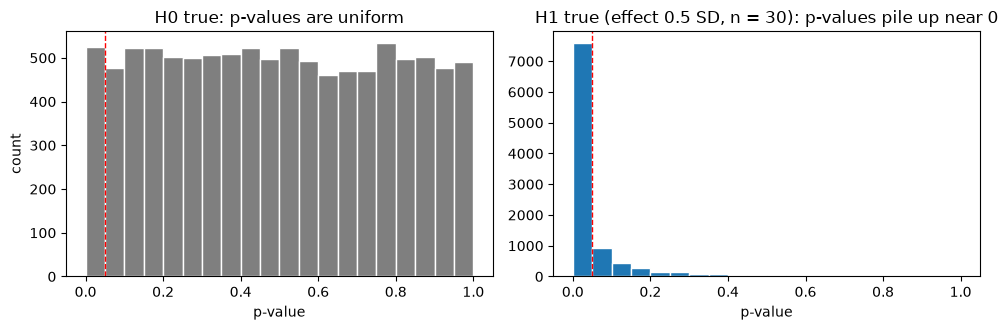

In [2]:
n, reps = 30, 10000
# 10,000 paired experiments: differences between two models on 30 paired runs
null_diffs = rng.normal(0.0, 1.0, size=(reps, n))          # H0 true: mean difference 0
alt_diffs = rng.normal(0.5, 1.0, size=(reps, n))           # H1 true: mean difference 0.5 SD
p_null = stats.ttest_1samp(null_diffs, 0, axis=1).pvalue
p_alt = stats.ttest_1samp(alt_diffs, 0, axis=1).pvalue
print(f"H0 true: share of p < 0.05 = {np.mean(p_null < 0.05):.3f}   (type I error rate, should be ~alpha = 0.05)")
print(f"H1 true: share of p < 0.05 = {np.mean(p_alt < 0.05):.3f}   (power); type II error rate = {np.mean(p_alt >= 0.05):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
axes[0].hist(p_null, bins=20, range=(0, 1), color="tab:gray", edgecolor="white")
axes[0].set_title("H0 true: p-values are uniform"); axes[0].set_xlabel("p-value"); axes[0].set_ylabel("count")
axes[1].hist(p_alt, bins=20, range=(0, 1), color="tab:blue", edgecolor="white")
axes[1].set_title("H1 true (effect 0.5 SD, n = 30): p-values pile up near 0"); axes[1].set_xlabel("p-value")
for ax in axes:
    ax.axvline(0.05, color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

**What just happened?** When H0 is true, p-values are **uniformly distributed**: every value between 0 and 1 is equally likely, so about 5% of them fall below 0.05 *by construction* (we got 0.052). That 5% is the type I error rate. With a real effect of half a standard deviation and 30 paired runs, 76% of experiments reach p < 0.05 (the **power**), and 24% miss the effect (type II errors).

### 1.3 Effect size vs significance

The **effect size** is *how big* the difference is (e.g. +0.3 accuracy points, or Cohen's d). **Significance** is *whether we can tell it apart from noise*. They answer different questions:

In [3]:
def demo(n, true_gain, sd=1.0):
    d = rng.normal(true_gain, sd, n)                             # n paired differences (in accuracy points)
    res = stats.ttest_1samp(d, 0)
    return d.mean(), res.pvalue

rows = []
for label, n, gain in [("tiny effect, huge n", 20000, 0.03), ("big effect, tiny n", 5, 0.8), ("big effect, decent n", 50, 0.8)]:
    m, p = demo(n, gain)
    rows.append({"scenario": label, "n": n, "true gain (points)": gain, "observed gain": round(m, 3), "p-value": f"{p:.2g}"})
print(pd.DataFrame(rows).to_string(index=False))

            scenario     n  true gain (points)  observed gain p-value
 tiny effect, huge n 20000                0.03           0.03 2.4e-05
  big effect, tiny n     5                0.80           0.78   0.064
big effect, decent n    50                0.80           0.80 9.1e-08


**What just happened?** A useless gain of 0.03 points is "highly significant" (p ≈ 0.00002) with 20,000 paired measurements, while a large gain of 0.8 points is *not* significant (p = 0.064) with only 5. With 50 measurements the same large gain is overwhelming (p ≈ 10⁻⁷). Always report the **effect size with a confidence interval**, not only a p-value.

### 1.4 Confidence intervals

A **95% confidence interval (CI)** is a range computed by a procedure that, over many repetitions of the experiment, contains the true value 95% of the time. For a mean with n observations: mean ± t₀.₉₇₅,ₙ₋₁ · s/√n. It shows the effect size *and* the uncertainty in one line, and if a 95% CI for a difference excludes 0, the two-sided test at α = 0.05 rejects H0.

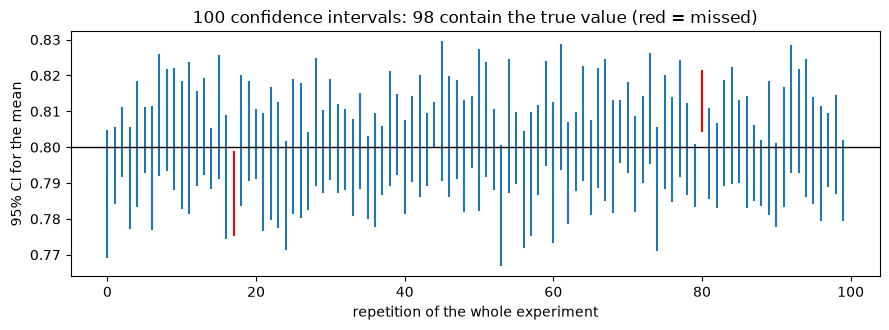

In [4]:
true_mean, n_obs, n_ci = 0.80, 10, 100                            # e.g. accuracy over 10 seeds
covered = []
fig, ax = plt.subplots(figsize=(9, 3.4))
for i in range(n_ci):
    x = rng.normal(true_mean, 0.02, n_obs)
    half = stats.t.ppf(0.975, n_obs - 1) * x.std(ddof=1) / np.sqrt(n_obs)   # half-width of the 95% CI
    lo, hi = x.mean() - half, x.mean() + half
    ok = lo <= true_mean <= hi
    covered.append(ok)
    ax.plot([i, i], [lo, hi], color="tab:blue" if ok else "red", lw=1.5)
ax.axhline(true_mean, color="black", lw=1)
ax.set_xlabel("repetition of the whole experiment"); ax.set_ylabel("95% CI for the mean")
ax.set_title(f"100 confidence intervals: {sum(covered)} contain the true value (red = missed)")
plt.tight_layout(); plt.show()

**What just happened?** Of 100 repeated experiments, 98 intervals contained the true mean of 0.80 and 2 (red) missed it, close to the promised 95% (with only 100 intervals, anything from about 90 to 99 is normal). Any *single* interval either contains the truth or not; the "95%" describes the procedure.

> 🎓 **Exam / interview tip:** "Is there a 95% probability that the true value is in *this* CI?" Strictly (frequentist), no: the true value is fixed, and 95% is the long-run success rate of the method. A Bayesian **credible interval** does have that interpretation (Section 6).

## 2. Comparing two models on one dataset

> **In plain English:** Pick a test that respects how your numbers were produced (shared folds, shared test set).

Our running example: a synthetic binary classification task (2,500 examples). We keep 1,000 examples as a **locked test set** and use the other 1,500 for cross-validation. Model **A** is a k-nearest-neighbours classifier (k = 15, scaled features), model **B** is a logistic regression. Both are fast, so we can afford many repetitions.

In [5]:
X, y = make_classification(n_samples=2500, n_features=20, n_informative=6, n_redundant=4,
                           flip_y=0.08, class_sep=0.8, random_state=1)
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=1000, random_state=SEED, stratify=y)

def model_A():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
def model_B():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 10 x 10 repeated stratified CV on the development set; both models see the SAME folds (paired)
cv10x10 = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
acc_A = cross_val_score(model_A(), X_dev, y_dev, cv=cv10x10)
acc_B = cross_val_score(model_B(), X_dev, y_dev, cv=cv10x10)
d_cv = acc_A - acc_B                                              # paired differences, one per fold
print(f"A (kNN, k = 15):        {acc_A.mean():.4f} ± {acc_A.std(ddof=1):.4f} over {len(acc_A)} folds")
print(f"B (logistic regression): {acc_B.mean():.4f} ± {acc_B.std(ddof=1):.4f}")
print(f"mean paired difference A - B: {d_cv.mean():.4f}, std {d_cv.std(ddof=1):.4f}")

A (kNN, k = 15):        0.8031 ± 0.0329 over 100 folds
B (logistic regression): 0.7836 ± 0.0337
mean paired difference A - B: 0.0195, std 0.0374


### 2.1 The paired t-test on CV folds, and why it is optimistic

The textbook **paired t-test** treats the k fold differences d₁…d_k as **independent**:

$$t = \frac{\bar d}{\sqrt{s^2/k}}, \qquad \text{df} = k - 1$$

But CV folds are **not independent**: any two training sets in 10-fold CV share 8/9 of their examples, and repeated CV re-uses the same examples again and again. The fold differences are positively correlated, so s²/k **underestimates** the variance of d̄ and the test rejects H0 far too often. Making k bigger (e.g. 10×10 = 100 folds) makes it *worse*, because the denominator shrinks while the information does not grow.

**Nadeau & Bengio (2003)** proposed the **corrected resampled t-test**, which inflates the variance with the test/train ratio:

$$t = \frac{\bar d}{\sqrt{\left(\dfrac{1}{k} + \dfrac{n_{\text{test}}}{n_{\text{train}}}\right) s^2}}, \qquad \text{df} = k - 1$$

For 10-fold CV, n_test / n_train = 1/9, which dominates 1/k when k = 100. We implement both and check the uncorrected version against `scipy.stats.ttest_rel`.

In [6]:
def resampled_ttest(diffs, n_train, n_test, corrected=True):
    # diffs: per-fold differences (A - B). Returns (t, two-sided p).
    d = np.asarray(diffs, dtype=float)
    k = len(d)
    var = d.var(ddof=1)                                         # sample variance s^2
    factor = (1 / k + n_test / n_train) if corrected else 1 / k  # Nadeau-Bengio correction
    t = d.mean() / np.sqrt(factor * var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return t, p

n_test_fold = len(y_dev) // 10                                  # 150 examples per test fold
n_train_fold = len(y_dev) - n_test_fold                         # 1,350 per training fold
t_naive, p_naive = resampled_ttest(d_cv, n_train_fold, n_test_fold, corrected=False)
t_corr, p_corr = resampled_ttest(d_cv, n_train_fold, n_test_fold, corrected=True)

# Check: the uncorrected version must equal SciPy's paired t-test exactly
ref = stats.ttest_rel(acc_A, acc_B)
assert np.isclose(t_naive, ref.statistic) and np.isclose(p_naive, ref.pvalue)
print(f"naive paired t-test:  t = {t_naive:.3f}, p = {p_naive:.2e}   (scipy.ttest_rel: t = {ref.statistic:.3f}, p = {ref.pvalue:.2e})")
print(f"corrected (N&B 2003): t = {t_corr:.3f}, p = {p_corr:.4f}")
print(f"variance inflation factor: {(1/100 + 1/9) / (1/100):.1f}x")

naive paired t-test:  t = 5.204, p = 1.06e-06   (scipy.ttest_rel: t = 5.204, p = 1.06e-06)
corrected (N&B 2003): t = 1.495, p = 0.1380
variance inflation factor: 12.1x


**What just happened?** The naive paired t-test (which matches SciPy exactly) reports t = 5.20 and p ≈ 0.000001, an overwhelming "win" for kNN. The corrected test reports t = 1.50 and **p = 0.138**: not significant. The correction multiplies the variance by 12.1, because 100 folds built from the same 1,500 examples are worth far less than 100 independent experiments.

But is the correction *right*? The way to check a test is to run it many times on situations where **H0 is true** and count how often it rejects. First, let's implement the other classic CV test.

### 2.2 Dietterich's 5×2cv paired t-test

**Dietterich (1998)** proposed: repeat 2-fold CV **5 times** (each repetition is a fresh random half/half split). In repetition i, let p_i⁽¹⁾ and p_i⁽²⁾ be the differences (A − B) on the two folds, p̄_i their mean and s_i² = (p_i⁽¹⁾ − p̄_i)² + (p_i⁽²⁾ − p̄_i)². Then

$$t = \frac{p_1^{(1)}}{\sqrt{\tfrac{1}{5}\sum_{i=1}^{5} s_i^2}} \sim t_5$$

The numerator uses only the *first* difference (to keep numerator and denominator independent under the null). Alpaydın (1999) proposed the more stable **combined 5×2cv F-test**: F = Σᵢ Σⱼ (p_i⁽ʲ⁾)² / (2 Σᵢ s_i²) ~ F(10, 5).

In [7]:
def five_by_two_stats(D):
    # D: 5 x 2 array of differences (A - B); row = repetition, column = fold
    D = np.asarray(D, dtype=float)
    pbar = D.mean(axis=1)                                         # mean of the two folds in each repetition
    s2 = ((D - pbar[:, None]) ** 2).sum(axis=1)                   # s_i^2
    t = D[0, 0] / np.sqrt(s2.mean())                              # Dietterich's t, df = 5
    p_t = 2 * stats.t.sf(abs(t), df=5)
    F = (D ** 2).sum() / (2 * s2.sum())                           # Alpaydin's combined F, df = (10, 5)
    p_F = stats.f.sf(F, 10, 5)
    return t, p_t, F, p_F

def paired_5x2cv(make_a, make_b, X, y, seed=0):
    D = np.zeros((5, 2))
    for i in range(5):
        folds = list(StratifiedKFold(2, shuffle=True, random_state=seed + i).split(X, y))
        for j, (tr, te) in enumerate(folds):
            D[i, j] = (make_a().fit(X[tr], y[tr]).score(X[te], y[te])
                       - make_b().fit(X[tr], y[tr]).score(X[te], y[te]))
    return D

# Check the arithmetic on a small hand example
D_hand = np.array([[0.02, 0.00], [0.01, 0.03], [0.00, 0.02], [0.02, 0.02], [0.01, 0.01]])
# s_i^2 = 0.0002, 0.0002, 0.0002, 0, 0 -> mean 0.00012; t = 0.02 / sqrt(0.00012) = 1.8257
t_h, _, F_h, _ = five_by_two_stats(D_hand)
assert np.isclose(t_h, 0.02 / np.sqrt(0.00012)) and np.isclose(F_h, (D_hand ** 2).sum() / (2 * 0.0006))

D_real = paired_5x2cv(model_A, model_B, X_dev, y_dev, seed=SEED)
t52, p52, F52, pF52 = five_by_two_stats(D_real)
print("5x2 differences (A - B):\n", D_real.round(4))
print(f"5x2cv t-test: t = {t52:.3f}, p = {p52:.4f} | combined 5x2cv F-test: F = {F52:.3f}, p = {pF52:.4f}")

5x2 differences (A - B):
 [[-0.0053  0.    ]
 [ 0.016   0.016 ]
 [ 0.0267  0.0133]
 [ 0.012   0.    ]
 [ 0.0307  0.012 ]]
5x2cv t-test: t = -0.638, p = 0.5515 | combined 5x2cv F-test: F = 3.804, p = 0.0766


**What just happened?** The hand example confirms the formulas (t = 0.02/√0.00012 = 1.826). On the real data kNN wins on 8 of the 10 half-splits, but the very first difference p₁⁽¹⁾ happens to be slightly *negative* (−0.005), so Dietterich's t is −0.64 (p = 0.55). This is the known weakness of the 5×2cv t-test: its numerator is a single fold, so it is noisy. The combined F-test, which uses all 10 differences, gives F = 3.80 and p = 0.077: suggestive, not significant, in line with the corrected resampled t-test (p = 0.138).

### 2.3 Do these tests keep their promise? A type-I-error simulation

We create a situation where **H0 is exactly true**: data with two *symmetric* groups of features (features 1–2 and 3–4 have identical distributions), model A uses group 1 and model B uses group 2, both nearest-centroid classifiers. By symmetry, the two models have the same expected accuracy, but on any given dataset one is luckier, which is exactly the correlation that fools the naive test. We draw 200 datasets of 300 examples and run each test.

naive paired t (10x10 CV)           0.525
corrected resampled t (10x10 CV)    0.015
5x2cv t-test                        0.020
5x2cv combined F-test               0.040

(Monte Carlo standard error around 0.05 with 200 simulations: ±0.015; took 14 s)


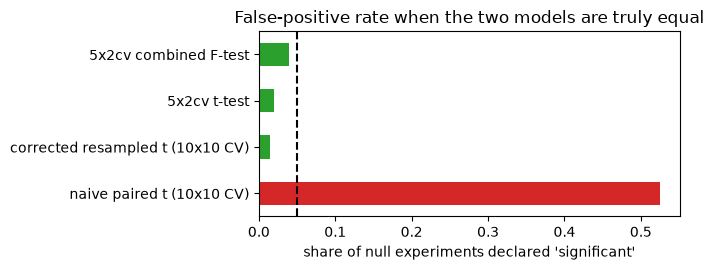

In [8]:
def make_symmetric(n, rng, shift=0.5):
    y = rng.integers(0, 2, n)
    X = rng.normal(0, 1, (n, 4)) + shift * (2 * y - 1)[:, None]   # all 4 features equally informative
    return X, y

def centroid_acc(Xtr, ytr, Xte, yte):
    c0, c1 = Xtr[ytr == 0].mean(0), Xtr[ytr == 1].mean(0)        # class centroids
    pred = ((Xte - c1) ** 2).sum(1) < ((Xte - c0) ** 2).sum(1)   # nearer to centroid 1 -> class 1
    return (pred == yte).mean()

def diff_on_split(X, y, tr, te):
    a = centroid_acc(X[tr][:, :2], y[tr], X[te][:, :2], y[te])   # model A: features 1-2
    b = centroid_acc(X[tr][:, 2:], y[tr], X[te][:, 2:], y[te])   # model B: features 3-4
    return a - b

sim_rng = np.random.default_rng(123)
n_sim, n_obs = 200, 300
reject = {"naive paired t (10x10 CV)": [], "corrected resampled t (10x10 CV)": [],
          "5x2cv t-test": [], "5x2cv combined F-test": []}
t_start = time.time()
for s in range(n_sim):
    Xs, ys = make_symmetric(n_obs, sim_rng)
    d = []
    for r in range(10):                                         # 10 x 10-fold CV
        perm = sim_rng.permutation(n_obs)
        folds = np.array_split(perm, 10)
        for i in range(10):
            te = folds[i]; tr = np.concatenate(folds[:i] + folds[i + 1:])
            d.append(diff_on_split(Xs, ys, tr, te))
    reject["naive paired t (10x10 CV)"].append(resampled_ttest(d, 270, 30, corrected=False)[1] < 0.05)
    reject["corrected resampled t (10x10 CV)"].append(resampled_ttest(d, 270, 30, corrected=True)[1] < 0.05)
    D = np.zeros((5, 2))                                        # 5 x 2-fold CV
    for i in range(5):
        perm = sim_rng.permutation(n_obs); h1, h2 = perm[:n_obs // 2], perm[n_obs // 2:]
        D[i] = [diff_on_split(Xs, ys, h1, h2), diff_on_split(Xs, ys, h2, h1)]
    _, p_t, _, p_F = five_by_two_stats(D)
    reject["5x2cv t-test"].append(p_t < 0.05)
    reject["5x2cv combined F-test"].append(p_F < 0.05)

type1 = pd.Series({k: np.mean(v) for k, v in reject.items()}, name="type I error rate (nominal 0.05)")
mc_se = np.sqrt(0.05 * 0.95 / n_sim)
print(type1.round(3).to_string())
print(f"\n(Monte Carlo standard error around 0.05 with {n_sim} simulations: ±{mc_se:.3f}; took {time.time() - t_start:.0f} s)")

ax = type1.plot(kind="barh", figsize=(7, 2.8), color=["tab:red", "tab:green", "tab:green", "tab:green"])
ax.axvline(0.05, color="black", ls="--"); ax.set_xlabel("share of null experiments declared 'significant'")
ax.set_title("False-positive rate when the two models are truly equal"); plt.tight_layout(); plt.show()

**What just happened?** With two genuinely equal models, the naive paired t-test on 10×10 CV declared a "significant" difference in **52.5%** of the datasets, more than ten times the promised 5%. The corrected resampled t-test (0.015), the 5×2cv t-test (0.020) and the combined F-test (0.040) all stay at or below the nominal 5%; they are somewhat **conservative** (they reject a little less often than 5%, which costs some power) but never anti-conservative. With 200 simulations the Monte Carlo error is about ±0.015, and in a longer run of 1,000 simulations during development the corrected test came out at 0.043. This reproduces, in miniature, the findings of Dietterich (1998) and Nadeau & Bengio (2003).

> ⚠️ **Common mistake:** "I ran 10-fold CV and a paired t-test on the 10 fold scores: p < 0.001." This is the naive test above. Use the corrected test (or 5×2cv), and say which one you used.

**Complexity:** r × k model fits for repeated k-fold CV (here 100 per model), 10 fits per model for 5×2cv; the tests themselves are O(k).

### 2.4 McNemar's test on a fixed test set

When both models are trained once and evaluated on the **same test set**, compare their **predictions** example by example. Only examples where they *disagree* matter:

| | B correct | B wrong |
|---|---|---|
| **A correct** | n₁₁ | **b** = n₁₀ |
| **A wrong** | **c** = n₀₁ | n₀₀ |

Under H0 (equal accuracy), a disagreement is equally likely to favour A or B, so b ~ Binomial(b + c, ½). **Exact McNemar:** p = 2 · P(X ≤ min(b, c)) for X ~ Bin(b + c, ½). **Asymptotic (with continuity correction):** χ² = (|b − c| − 1)² / (b + c) ~ χ²₁.

In [9]:
def mcnemar_test(correct_a, correct_b, exact=True):
    correct_a, correct_b = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    b = int(np.sum(correct_a & ~correct_b))                      # A right, B wrong
    c = int(np.sum(~correct_a & correct_b))                      # A wrong, B right
    if exact:
        p = min(1.0, 2 * stats.binom.cdf(min(b, c), b + c, 0.5))
        return b, c, None, p
    chi2 = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, chi2, stats.chi2.sf(chi2, df=1)

fit_A = model_A().fit(X_dev, y_dev)                             # final models: trained on all development data
fit_B = model_B().fit(X_dev, y_dev)
pred_A, pred_B = fit_A.predict(X_test), fit_B.predict(X_test)
prob_A, prob_B = fit_A.predict_proba(X_test)[:, 1], fit_B.predict_proba(X_test)[:, 1]
corr_A, corr_B = pred_A == y_test, pred_B == y_test
print(f"test accuracy: A = {corr_A.mean():.3f}, B = {corr_B.mean():.3f}, difference = {corr_A.mean() - corr_B.mean():+.3f}")

b, c, _, p_exact = mcnemar_test(corr_A, corr_B, exact=True)
_, _, chi2, p_chi2 = mcnemar_test(corr_A, corr_B, exact=False)
table = [[int(np.sum(corr_A & corr_B)), b], [c, int(np.sum(~corr_A & ~corr_B))]]
print("contingency table [[both right, A only], [B only, both wrong]]:", table)
print(f"ours:  exact p = {p_exact:.5f} | chi2 = {chi2:.3f}, p = {p_chi2:.5f}")
assert np.isclose(p_exact, stats.binomtest(b, b + c, 0.5).pvalue)   # same as SciPy's exact binomial test
if HAS_SM:
    r_exact = sm_mcnemar(table, exact=True)
    r_chi2 = sm_mcnemar(table, exact=False, correction=True)
    assert np.isclose(p_exact, r_exact.pvalue) and np.isclose(chi2, r_chi2.statistic) and np.isclose(p_chi2, r_chi2.pvalue)
    print(f"statsmodels: exact p = {r_exact.pvalue:.5f} | chi2 = {r_chi2.statistic:.3f}, p = {r_chi2.pvalue:.5f}  -> match")

test accuracy: A = 0.828, B = 0.795, difference = +0.033
contingency table [[both right, A only], [B only, both wrong]]: [[732, 96], [63, 109]]
ours:  exact p = 0.01092 | chi2 = 6.440, p = 0.01116
statsmodels: exact p = 0.01092 | chi2 = 6.440, p = 0.01116  -> match


**What just happened?** On the 1,000-example test set kNN is right on 96 examples where logistic regression is wrong (b), and the reverse happens 63 times (c). Under H0 we would expect about 79.5 each way. The exact McNemar p-value is 0.011 and the χ² version 0.011, matched by `scipy.stats.binomtest` and statsmodels to many decimals. So on *this* test set, kNN's 3.3-point accuracy gain is significant.

Notice that this disagrees with the corrected CV test (p = 0.138). There is no contradiction: they answer **different questions** (Dietterich, 1998). McNemar takes the two *trained models* as fixed and asks whether their accuracies differ on the population the test set came from; its only randomness is the test sample. The CV tests ask whether the two *learning algorithms* differ when trained on new training sets of this size, which also includes training-set variability. A thesis comparing *methods* should care about the second question; a team choosing *which trained model to deploy* cares about the first.

**Complexity:** O(n) to count the table; the exact p-value is a binomial CDF.

### 2.5 Bootstrap confidence intervals for any metric

**Intuition.** We cannot re-collect the test set 1,000 times, but we can *simulate* re-collecting it by resampling it **with replacement**. The spread of the metric across resamples estimates its sampling uncertainty.

**Percentile bootstrap:** draw B resamples of size n (with replacement), compute the metric on each, and take the 2.5th and 97.5th percentiles as a 95% CI. It works for metrics with no simple formula, such as **F1** and **AUC**. We implement fast, vectorised metric functions and check them against scikit-learn.

In [10]:
def f1_binary(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1), axis=-1)
    fp = np.sum((y_pred == 1) & (y_true == 0), axis=-1)
    fn = np.sum((y_pred == 0) & (y_true == 1), axis=-1)
    return 2 * tp / (2 * tp + fp + fn)                             # works on 1-D arrays or rows of a 2-D array

def auc_rank(y_true, score):
    # AUC = P(score of a random positive > score of a random negative) = Mann-Whitney U / (n_pos * n_neg)
    ranks = stats.rankdata(score)                                  # average ranks handle ties
    n_pos = y_true.sum(); n_neg = len(y_true) - n_pos
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

assert np.isclose(f1_binary(y_test, pred_A), f1_score(y_test, pred_A))
assert np.isclose(auc_rank(y_test, prob_A), roc_auc_score(y_test, prob_A))

def bootstrap_ci(y_true, pred, prob, B=2000, alpha=0.05, rng=None):
    rng = rng or np.random.default_rng(SEED)
    n = len(y_true)
    idx = rng.integers(0, n, size=(B, n))                          # B resamples of row indices
    yt, yp = y_true[idx], pred[idx]
    dist = {"accuracy": (yt == yp).mean(axis=1),
            "F1": f1_binary(yt, yp),
            "AUC": np.array([auc_rank(y_true[i], prob[i]) for i in idx])}
    point = {"accuracy": (y_true == pred).mean(), "F1": f1_binary(y_true, pred), "AUC": auc_rank(y_true, prob)}
    return pd.DataFrame({m: {"estimate": point[m], "CI low": np.quantile(v, alpha / 2), "CI high": np.quantile(v, 1 - alpha / 2),
                             "bootstrap SE": v.std(ddof=1)} for m, v in dist.items()}).T

ci_A = bootstrap_ci(y_test, pred_A, prob_A)
ci_B = bootstrap_ci(y_test, pred_B, prob_B)
print("Model A (kNN, k = 15)\n", ci_A.round(4).to_string(), "\n")
print("Model B (logistic regression)\n", ci_B.round(4).to_string())

Model A (kNN, k = 15)
           estimate  CI low  CI high  bootstrap SE
accuracy    0.8280  0.8040   0.8510        0.0121
F1          0.8410  0.8166   0.8639        0.0120
AUC         0.8892  0.8670   0.9083        0.0105 

Model B (logistic regression)
           estimate  CI low  CI high  bootstrap SE
accuracy    0.7950  0.7700   0.8190        0.0129
F1          0.8049  0.7771   0.8290        0.0136
AUC         0.8721  0.8492   0.8929        0.0112


In [11]:
# Cross-check with SciPy's bootstrap (independent random resamples, so endpoints agree only approximately)
res_pct = stats.bootstrap((y_test, pred_A), lambda a, b: np.mean(a == b), paired=True, vectorized=False,
                          n_resamples=2000, method="percentile", random_state=1)
res_bca = stats.bootstrap((y_test, prob_A), auc_rank, paired=True, vectorized=False,
                          n_resamples=2000, method="BCa", random_state=1)
ours = ci_A.loc["accuracy", ["CI low", "CI high"]].to_numpy()
theirs = np.array([res_pct.confidence_interval.low, res_pct.confidence_interval.high])
print(f"accuracy 95% CI  ours {ours.round(4)}  scipy percentile {theirs.round(4)}")
print(f"AUC 95% CI       ours {ci_A.loc['AUC', ['CI low', 'CI high']].to_numpy().round(4)}  scipy BCa "
      f"[{res_bca.confidence_interval.low:.4f} {res_bca.confidence_interval.high:.4f}]")
assert np.all(np.abs(ours - theirs) < 0.006), "bootstrap CIs should agree within Monte Carlo error"

accuracy 95% CI  ours [0.804 0.851]  scipy percentile [0.805 0.851]
AUC 95% CI       ours [0.867  0.9083]  scipy BCa [0.8680 0.9079]


**What just happened?** Each metric now comes with a 95% CI. Model A: accuracy 0.828 [0.804, 0.851], F1 0.841 [0.817, 0.864], AUC 0.889 [0.867, 0.908]. Model B: accuracy 0.795 [0.770, 0.819], AUC 0.872 [0.849, 0.893]. SciPy's independent bootstrap gives almost the same accuracy interval ([0.805, 0.851]), and its **BCa** (bias-corrected and accelerated) interval for AUC ([0.868, 0.908]) is close to our percentile interval. BCa adjusts for skew and bias and is usually preferred for small samples or bounded metrics near 0 or 1.

⚠️ The two models' accuracy CIs **overlap** (0.804–0.851 vs 0.770–0.819). That does **not** prove they are equally good, and two separate CIs are the wrong tool for comparing them: they ignore that both models were evaluated on the *same* examples. Compare them with a **paired** method.

**Complexity:** O(B · n) for accuracy and F1 (vectorised), O(B · n log n) for AUC (sorting per resample).

### 2.6 The paired bootstrap

Resample test **examples** (the same indices for both models) and compute the *difference* in the metric each time. The CI of the difference answers the real question directly. A common one-sided "p-value" from it is the share of resamples where the difference is ≤ 0 (Koehn, 2004; Berg-Kirkpatrick et al., 2012 discuss its use in NLP).

In [12]:
def paired_bootstrap(y_true, out_a, out_b, metric, B=2000, rng=None):
    rng = rng or np.random.default_rng(SEED)
    n = len(y_true)
    diffs = np.empty(B)
    for i in range(B):
        idx = rng.integers(0, n, n)                                 # SAME resample for both models
        diffs[i] = metric(y_true[idx], out_a[idx]) - metric(y_true[idx], out_b[idx])
    return metric(y_true, out_a) - metric(y_true, out_b), diffs

acc = lambda yt, yp: np.mean(yt == yp)
rows = {}
for name, oa, ob, m in [("accuracy", pred_A, pred_B, acc), ("F1", pred_A, pred_B, f1_binary), ("AUC", prob_A, prob_B, auc_rank)]:
    obs, diffs = paired_bootstrap(y_test, oa, ob, m)
    lo, hi = np.quantile(diffs, [0.025, 0.975])
    rows[name] = {"A - B": obs, "95% CI low": lo, "95% CI high": hi, "share of resamples with A <= B": np.mean(diffs <= 0)}
paired_tbl = pd.DataFrame(rows).T
print(paired_tbl.round(4).to_string())

           A - B  95% CI low  95% CI high  share of resamples with A <= B
accuracy  0.0330      0.0090       0.0590                          0.0070
F1        0.0361      0.0127       0.0601                          0.0010
AUC       0.0171     -0.0006       0.0357                          0.0295


**What just happened?** The paired 95% CI for the accuracy difference is [+0.009, +0.059]: it excludes 0, consistent with McNemar (p = 0.011), even though the two separate CIs overlapped. Pairing removes the noise shared by both models (examples that are easy or hard for both). F1 behaves the same way ([+0.013, +0.060]). For **AUC**, the paired difference of +0.017 has a CI of [−0.001, +0.036] that just includes 0: the evidence that kNN *ranks* examples better is weaker than the evidence for its accuracy. Different metrics can lead to different conclusions, which is why the primary metric must be fixed in advance.

### 2.7 Permutation (randomisation) test

**Idea.** If H0 is true (the models are interchangeable), then for each test example, *which* model produced which output is arbitrary. Randomly **swap** the two models' outputs on each example (a coin flip per example), recompute the difference, and repeat many times. The p-value is the share of shuffled differences at least as extreme as the observed one. It makes almost no assumptions.

observed accuracy difference: +0.0330
ours: p = 0.0110 | scipy.stats.permutation_test: p = 0.0124 | exact McNemar: p = 0.0109


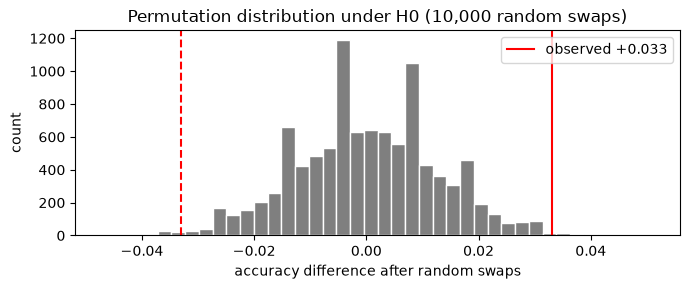

In [13]:
def paired_permutation_test(score_a, score_b, R=10000, rng=None):
    # score_a, score_b: per-example scores (e.g. 1 = correct, 0 = wrong) of the two models on the same examples
    rng = rng or np.random.default_rng(SEED)
    d = np.asarray(score_a, float) - np.asarray(score_b, float)
    observed = d.mean()
    signs = rng.choice([-1.0, 1.0], size=(R, len(d)))              # swapping A and B flips the sign of d_i
    perm_stats = (signs * d).mean(axis=1)
    p = (np.sum(np.abs(perm_stats) >= abs(observed) - 1e-12) + 1) / (R + 1)   # +1: count the observed arrangement
    return observed, p, perm_stats

obs, p_perm, perm_stats = paired_permutation_test(corr_A, corr_B)
res_sp = stats.permutation_test((corr_A.astype(float), corr_B.astype(float)), lambda a, b, axis: np.mean(a - b, axis=axis),
                                permutation_type="samples", vectorized=True, n_resamples=10000, random_state=2)
print(f"observed accuracy difference: {obs:+.4f}")
print(f"ours: p = {p_perm:.4f} | scipy.stats.permutation_test: p = {res_sp.pvalue:.4f} | exact McNemar: p = {p_exact:.4f}")
assert abs(p_perm - res_sp.pvalue) < 0.02, "the two Monte Carlo p-values should agree within sampling error"

plt.figure(figsize=(7, 3))
plt.hist(perm_stats, bins=40, color="tab:gray", edgecolor="white")
plt.axvline(obs, color="red", label=f"observed {obs:+.3f}"); plt.axvline(-obs, color="red", ls="--")
plt.xlabel("accuracy difference after random swaps"); plt.ylabel("count")
plt.title("Permutation distribution under H0 (10,000 random swaps)"); plt.legend(); plt.tight_layout(); plt.show()

**What just happened?** In 10,000 random swaps, a difference at least as large as the observed 0.033 occurred about 1.1% of the time (p = 0.011). SciPy's `permutation_test` gives p = 0.012 (the same up to Monte Carlo noise), and both agree with the exact McNemar test (0.011). That is no coincidence: for accuracy, the sign-flip permutation test and McNemar's test test the same hypothesis. The permutation test's advantage is that it works for **any** per-example score (BLEU per sentence, error per example, a rubric score from a human judge).

**Complexity:** O(R · n) for R permutations.

## 3. Many models on many datasets: Friedman + Nemenyi (Demšar, 2006)

> **In plain English:** Rank the models on every dataset and ask whether the average ranks differ by more than luck.

To claim a method is better *in general*, papers compare k methods on N datasets. Averaging accuracies across datasets is misleading (a 1-point gain on an easy dataset is not the same as on a hard one), and running a t-test for every pair inflates false positives. **Demšar (2006)** recommends:

1. Rank the k methods on each dataset (1 = best; ties get the average rank).
2. **Friedman test:** are the average ranks R_j more different than chance? With N datasets:

$$\chi^2_F = \frac{12N}{k(k+1)}\left[\sum_j R_j^2 - \frac{k(k+1)^2}{4}\right] \sim \chi^2_{k-1}$$

   Iman & Davenport's less conservative version: F_F = (N − 1)χ²_F / (N(k − 1) − χ²_F) ~ F(k − 1, (k − 1)(N − 1)).
3. If Friedman rejects, the **Nemenyi post-hoc test**: two methods differ significantly if their average ranks differ by at least the **critical difference**

$$CD = q_\alpha \sqrt{\frac{k(k+1)}{6N}}$$

   where q_α is the studentized range quantile divided by √2.
4. Show it in a **critical-difference (CD) diagram**.

Let's build a real benchmark: **5 classifiers on 15 datasets** (4 classic scikit-learn datasets + 11 synthetic ones with different sizes, noise and shapes), each evaluated with 5-fold stratified CV.

In [14]:
datasets = {
    "iris": load_iris(return_X_y=True), "wine": load_wine(return_X_y=True),
    "breast_cancer": load_breast_cancer(return_X_y=True), "digits": load_digits(return_X_y=True),
    "moons": make_moons(400, noise=0.3, random_state=0), "circles": make_circles(400, noise=0.15, factor=0.5, random_state=0),
}
synth_settings = [(300, 10, 3, 0.05, 1.0), (500, 20, 5, 0.10, 0.8), (400, 40, 4, 0.05, 1.2), (600, 8, 6, 0.15, 1.0),
                  (300, 30, 10, 0.02, 0.6), (800, 15, 3, 0.10, 1.5), (500, 50, 5, 0.05, 1.0), (350, 12, 8, 0.20, 1.0),
                  (450, 25, 2, 0.05, 0.7)]
for i, (n, f, inf, flip, sep) in enumerate(synth_settings):
    datasets[f"synthetic_{i + 1}"] = make_classification(n_samples=n, n_features=f, n_informative=inf, n_redundant=0,
                                                         flip_y=flip, class_sep=sep, random_state=10 + i)
models = {
    "NaiveBayes": lambda: GaussianNB(),
    "kNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "DecisionTree": lambda: DecisionTreeClassifier(random_state=SEED),
    "RandomForest": lambda: RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=1),
}
fold_acc = {}                                                    # (dataset, model) -> 5 fold accuracies
t_start = time.time()
for dname, (Xd, yd) in datasets.items():
    cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)  # same folds for every model (blocking)
    for mname, make in models.items():
        fold_acc[(dname, mname)] = cross_val_score(make(), Xd, yd, cv=cv5)
bench = pd.DataFrame({m: {d: fold_acc[(d, m)].mean() for d in datasets} for m in models})
print(f"{len(datasets)} datasets x {len(models)} models evaluated in {time.time() - t_start:.0f} s\n")
print(bench.round(3).to_string())

15 datasets x 5 models evaluated in 28 s

               NaiveBayes    kNN  LogReg  DecisionTree  RandomForest
iris                0.960  0.960   0.960         0.933         0.947
wine                0.972  0.955   0.983         0.927         0.978
breast_cancer       0.939  0.965   0.979         0.926         0.961
digits              0.851  0.974   0.969         0.859         0.974
moons               0.852  0.885   0.852         0.872         0.888
circles             0.955  0.952   0.450         0.915         0.943
synthetic_1         0.833  0.790   0.847         0.827         0.863
synthetic_2         0.596  0.664   0.598         0.634         0.674
synthetic_3         0.920  0.798   0.873         0.862         0.915
synthetic_4         0.683  0.810   0.658         0.720         0.793
synthetic_5         0.647  0.690   0.633         0.620         0.707
synthetic_6         0.679  0.760   0.766         0.831         0.861
synthetic_7         0.848  0.758   0.864         0.796       

In [15]:
def friedman_nemenyi(scores, alpha=0.05):
    # scores: N datasets x k methods (higher = better). Returns average ranks and test results.
    S = np.asarray(scores, float)
    N, k = S.shape
    ranks = np.vstack([stats.rankdata(-row) for row in S])         # rank 1 = best; ties get average ranks
    R = ranks.mean(axis=0)
    chi2 = 12 * N / (k * (k + 1)) * (np.sum(R ** 2) - k * (k + 1) ** 2 / 4)
    # tie correction (makes it identical to scipy.stats.friedmanchisquare)
    ties = sum(np.sum(c ** 3 - c) for c in (np.unique(row, return_counts=True)[1] for row in S))
    chi2 = chi2 / (1 - ties / (N * k * (k ** 2 - 1)))
    p_chi2 = stats.chi2.sf(chi2, k - 1)
    FF = (N - 1) * chi2 / (N * (k - 1) - chi2)                     # Iman-Davenport
    p_FF = stats.f.sf(FF, k - 1, (k - 1) * (N - 1))
    q_alpha = stats.studentized_range.ppf(1 - alpha, k, np.inf) / np.sqrt(2)
    CD = q_alpha * np.sqrt(k * (k + 1) / (6 * N))
    return R, chi2, p_chi2, FF, p_FF, q_alpha, CD, ranks

R, chi2_F, p_F, FF, p_FF, q_a, CD, rank_matrix = friedman_nemenyi(bench.values)
ref = stats.friedmanchisquare(*bench.values.T)
assert np.isclose(chi2_F, ref.statistic) and np.isclose(p_F, ref.pvalue), (chi2_F, ref)
# Demsar (2006), Table 5(a): q_0.05 for k = 2..6 and 10
for k, q in {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 10: 3.164}.items():
    assert abs(stats.studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) - q) < 0.002
avg_rank = pd.Series(R, index=bench.columns).sort_values()
print("average ranks (1 = best):\n", avg_rank.round(2).to_string())
print(f"\nFriedman chi2 = {chi2_F:.2f}, p = {p_F:.2e} (scipy: {ref.statistic:.2f}, p = {ref.pvalue:.2e})")
print(f"Iman-Davenport F = {FF:.2f}, p = {p_FF:.2e}")
print(f"Nemenyi: q_0.05 = {q_a:.3f}, critical difference CD = {CD:.3f} for k = {len(R)}, N = {len(bench)}")

average ranks (1 = best):
 RandomForest    1.67
kNN             2.93
LogReg          3.07
NaiveBayes      3.33
DecisionTree    4.00

Friedman chi2 = 17.50, p = 1.54e-03 (scipy: 17.50, p = 1.54e-03)
Iman-Davenport F = 5.77, p = 5.86e-04
Nemenyi: q_0.05 = 2.728, critical difference CD = 1.575 for k = 5, N = 15


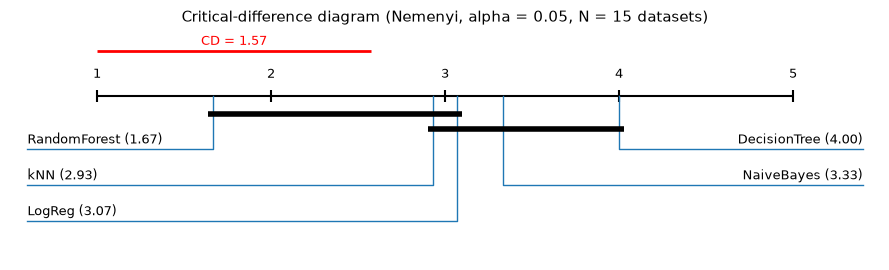

groups NOT significantly different (thick bars): [['RandomForest', 'kNN', 'LogReg'], ['kNN', 'LogReg', 'NaiveBayes', 'DecisionTree']]
  significant: RandomForest (rank 1.67) better than NaiveBayes (rank 3.33)
  significant: RandomForest (rank 1.67) better than DecisionTree (rank 4.00)


In [16]:
def cd_diagram(avg_ranks, cd, title):
    # avg_ranks: pd.Series sorted ascending (best first). Draws a Demsar-style critical-difference diagram.
    names, ranks = list(avg_ranks.index), avg_ranks.to_numpy()
    k = len(ranks)
    fig, ax = plt.subplots(figsize=(9, 2.8))
    ax.set_xlim(0.5, k + 0.5); ax.set_ylim(0.25, 1.02); ax.axis("off")
    ax.hlines(0.8, 1, k, color="black")                             # the rank axis
    for r in range(1, k + 1):
        ax.vlines(r, 0.78, 0.82, color="black"); ax.text(r, 0.86, str(r), ha="center", fontsize=9)
    half = (k + 1) // 2
    for i, (n, r) in enumerate(zip(names, ranks)):                  # left half labelled on the left, rest on the right
        y = 0.62 - 0.12 * (i if i < half else k - 1 - i)
        x_text = 0.6 if i < half else k + 0.4
        ax.plot([r, r, x_text], [0.8, y, y], color="tab:blue", lw=1)
        ax.text(x_text, y + 0.02, f"{n} ({r:.2f})", ha="left" if i < half else "right", fontsize=9)
    ax.hlines(0.95, 1, 1 + cd, color="red", lw=2); ax.text(1 + cd / 2, 0.97, f"CD = {cd:.2f}", ha="center", color="red", fontsize=9)
    # cliques: maximal groups whose rank range is below CD (not significantly different)
    cliques = []
    for i in range(k):
        j = max(j for j in range(i, k) if ranks[j] - ranks[i] < cd)
        if j > i and not any(a <= i and j <= b for a, b in cliques):
            cliques.append((i, j))
    for c_i, (a, b) in enumerate(cliques):
        yb = 0.74 - 0.05 * c_i
        ax.hlines(yb, ranks[a] - 0.03, ranks[b] + 0.03, color="black", lw=4)
    ax.set_title(title, fontsize=11)
    plt.tight_layout(); plt.show()
    return [[names[x] for x in range(a, b + 1)] for a, b in cliques]

groups = cd_diagram(avg_rank, CD, f"Critical-difference diagram (Nemenyi, alpha = 0.05, N = {len(bench)} datasets)")
print("groups NOT significantly different (thick bars):", groups)
for i, m1 in enumerate(avg_rank.index):
    for m2 in avg_rank.index[i + 1:]:
        if avg_rank[m2] - avg_rank[m1] >= CD:
            print(f"  significant: {m1} (rank {avg_rank[m1]:.2f}) better than {m2} (rank {avg_rank[m2]:.2f})")

**What just happened?** Our Friedman statistic equals SciPy's exactly (χ²_F = 17.50, p = 0.0015), and our q_α values match Demšar's published table. The average ranks are RandomForest 1.67, kNN 2.93, LogReg 3.07, NaiveBayes 3.33 and DecisionTree 4.00. With k = 5 and N = 15 the critical difference is **1.575** ranks, so:

- RandomForest is **significantly better** than NaiveBayes and DecisionTree (rank gaps 1.67 and 2.33);
- the thick bars join methods whose ranks differ by less than CD: {RandomForest, kNN, LogReg} and {kNN, LogReg, NaiveBayes, DecisionTree}. kNN and LogReg cannot be separated from either group with only 15 datasets.
- Note the circles dataset: logistic regression scores 0.450 there (a linear model cannot separate concentric circles). Ranks limit the influence of such an extreme value; a mean accuracy would be dragged down by it.

**How to read a CD diagram:** the axis shows average ranks (left = better); methods joined by a thick bar are **not** significantly different. It summarises 5 × 15 = 75 numbers and 10 pairwise comparisons in one figure, which is why it is popular in ML papers.

For **two** methods over many datasets, Demšar recommends the **Wilcoxon signed-rank test** on the per-dataset differences:

In [17]:
w = stats.wilcoxon(bench["RandomForest"], bench["kNN"])
wins = int((bench["RandomForest"] > bench["kNN"]).sum()); losses = int((bench["RandomForest"] < bench["kNN"]).sum())
print(f"RandomForest vs kNN over {len(bench)} datasets: wins/ties/losses = {wins}/{len(bench) - wins - losses}/{losses}, "
      f"Wilcoxon p = {w.pvalue:.3f}")

RandomForest vs kNN over 15 datasets: wins/ties/losses = 11/0/4, Wilcoxon p = 0.038


**What just happened?** Head to head, the random forest beats kNN on 11 datasets and loses on 4, and the Wilcoxon test gives p = 0.038, significant at 0.05, although Nemenyi did *not* separate them (rank gap 1.26 < CD 1.575). Again no contradiction: Nemenyi protects all 10 pairwise comparisons at once and is therefore conservative, while a *single, pre-planned* comparison (e.g. "our method vs the strongest baseline") can use a more powerful test. If you test several pairs with Wilcoxon, correct with Holm (Section 4). A **win/tie/loss** count is a simple, honest addition to any multi-dataset table.

> 🎓 **Exam / interview tip:** "Why ranks and not mean accuracy across datasets?" Ranks are scale-free (a dataset where everyone scores 0.99 counts the same as one where everyone scores 0.6), robust to outliers, and do not assume the accuracies are commensurable or normally distributed across datasets.

**Complexity:** ranking is O(N · k log k); the Friedman statistic is O(N · k).

## 4. Multiple comparisons

> **In plain English:** The more tests you run, the more lucky 'winners' you find, unless you correct for it.

**Intuition.** Buy one lottery ticket and you will probably lose; buy 20 and your chance of *some* win goes up. Run 20 tests at α = 0.05 when nothing is going on, and the chance of *at least one* "significant" result is 1 − 0.95²⁰ ≈ **0.64**.

| Quantity | Definition | Controlled by |
|---|---|---|
| **FWER** (family-wise error rate) | P(at least one false positive among the m tests) | **Bonferroni**, **Holm** |
| **FDR** (false discovery rate) | expected share of false positives *among the rejected* hypotheses | **Benjamini–Hochberg** |

- **Bonferroni:** reject H_i if p_i ≤ α/m. Adjusted p: min(1, m · p_i). Simple, conservative.
- **Holm (step-down):** sort p-values p₍₁₎ ≤ … ≤ p₍ₘ₎; adjusted p₍ᵢ₎ = max over j ≤ i of min(1, (m − j + 1) p₍ⱼ₎). Same FWER guarantee as Bonferroni and **always at least as powerful**, so there is little reason to use plain Bonferroni.
- **Benjamini–Hochberg (step-up):** adjusted p₍ᵢ₎ = min over j ≥ i of min(1, m · p₍ⱼ₎ / j). Controls FDR (for independent or positively dependent tests); much more powerful when there are many real effects.

Worked example by hand, m = 4, p = (0.01, 0.04, 0.03, 0.005), α = 0.05:

| sorted p | Bonferroni (×4) | Holm multiplier | Holm adjusted | BH: m·p/rank | BH adjusted |
|---|---|---|---|---|---|
| 0.005 | 0.020 | ×4 → 0.020 | 0.020 | 4·0.005/1 = 0.020 | 0.020 |
| 0.010 | 0.040 | ×3 → 0.030 | 0.030 | 4·0.010/2 = 0.020 | 0.020 |
| 0.030 | 0.120 | ×2 → 0.060 | 0.060 | 4·0.030/3 = 0.040 | 0.040 |
| 0.040 | 0.160 | ×1 → 0.040, but max with 0.060 | 0.060 | 4·0.040/4 = 0.040 | 0.040 |

Bonferroni and Holm reject 2 hypotheses, BH rejects all 4.

In [18]:
def bonferroni(p):
    p = np.asarray(p, float)
    return np.minimum(1.0, p * len(p))

def holm(p):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    adj_sorted = np.maximum.accumulate(np.minimum(1.0, (m - np.arange(m)) * p[order]))   # step-down, keep monotone
    adj = np.empty(m); adj[order] = adj_sorted
    return adj

def benjamini_hochberg(p):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    raw = p[order] * m / np.arange(1, m + 1)
    adj_sorted = np.minimum(1.0, np.minimum.accumulate(raw[::-1])[::-1])                 # step-up: min from the end
    adj = np.empty(m); adj[order] = adj_sorted
    return adj

p_hand = [0.01, 0.04, 0.03, 0.005]
print("Bonferroni:", bonferroni(p_hand).round(3), "| Holm:", holm(p_hand).round(3), "| BH:", benjamini_hochberg(p_hand).round(3))
assert np.allclose(holm(p_hand), [0.03, 0.06, 0.06, 0.02]) and np.allclose(benjamini_hochberg(p_hand), [0.02, 0.04, 0.04, 0.02])

if HAS_SM:                                                       # check on 60 random p-value vectors
    chk = np.random.default_rng(7)
    for _ in range(60):
        pv = chk.uniform(0, 0.2, chk.integers(2, 30))
        for ours, method in [(bonferroni, "bonferroni"), (holm, "holm"), (benjamini_hochberg, "fdr_bh")]:
            assert np.allclose(ours(pv), multipletests(pv, method=method)[1])
    print("Bonferroni, Holm and BH match statsmodels.multipletests on 60 random cases")

Bonferroni: [0.04 0.16 0.12 0.02] | Holm: [0.03 0.06 0.06 0.02] | BH: [0.02 0.04 0.04 0.02]


Bonferroni, Holm and BH match statsmodels.multipletests on 60 random cases


**What just happened?** The implementations reproduce the hand table (Holm: 0.03, 0.06, 0.06, 0.02; BH: 0.02, 0.04, 0.04, 0.02) and agree with statsmodels on 60 random p-value vectors.

### 4.1 Demo: false discoveries from running 20 tests

A student tries **20 tweaks** of a model (different features, losses, augmentations). In truth **none** helps. Each tweak is compared with the baseline using 15 paired seeds and a paired t-test.

In [19]:
demo_rng = np.random.default_rng(2024)
m_tests, n_seeds = 20, 15
diffs20 = demo_rng.normal(0, 0.01, size=(m_tests, n_seeds))       # true effect 0 for every tweak
p20 = stats.ttest_1samp(diffs20, 0, axis=1).pvalue
tbl20 = pd.DataFrame({"raw p": p20, "Bonferroni": bonferroni(p20), "Holm": holm(p20), "BH": benjamini_hochberg(p20)},
                     index=[f"tweak {i + 1}" for i in range(m_tests)]).sort_values("raw p")
print(tbl20.head(5).round(4).to_string())
print("\n'significant' at 0.05 ->", {c: int((tbl20[c] < 0.05).sum()) for c in tbl20.columns})

# Repeat the whole 20-test study 5,000 times to measure the family-wise error rate
fam = np.random.default_rng(99).normal(0, 0.01, size=(5000, m_tests, n_seeds))
P = stats.ttest_1samp(fam, 0, axis=2).pvalue
fwer = {"no correction": np.mean((P < 0.05).any(1)),
        "Bonferroni": np.mean((P < 0.05 / m_tests).any(1)),
        "Holm": np.mean([(holm(row) < 0.05).any() for row in P]),
        "BH": np.mean([(benjamini_hochberg(row) < 0.05).any() for row in P])}
print("\nP(at least one false positive) over 5,000 studies:", {k: round(float(v), 3) for k, v in fwer.items()},
      f"| theory without correction: {1 - 0.95 ** 20:.3f}")

           raw p  Bonferroni    Holm      BH
tweak 14  0.0214      0.4277  0.4277  0.3387
tweak 11  0.0339      0.6773  0.6434  0.3387
tweak 2   0.1107      1.0000  1.0000  0.4868
tweak 9   0.1316      1.0000  1.0000  0.4868
tweak 4   0.1326      1.0000  1.0000  0.4868

'significant' at 0.05 -> {'raw p': 2, 'Bonferroni': 0, 'Holm': 0, 'BH': 0}



P(at least one false positive) over 5,000 studies: {'no correction': 0.638, 'Bonferroni': 0.05, 'Holm': 0.05, 'BH': 0.051} | theory without correction: 0.642


**What just happened?** In this one study, **tweak 14 reached raw p = 0.021 and tweak 11 p = 0.034**: without correction the student would write "tweaks 14 and 11 significantly improve the model". After Bonferroni, Holm or BH, no tweak survives (smallest adjusted p = 0.34). Repeating the whole study 5,000 times shows the general pattern: without correction, **63.8%** of studies report at least one false discovery (theory: 0.642); with any of the three corrections it is about 5% (0.050, 0.050, 0.051). (When *all* nulls are true, FDR and FWER coincide, so BH also gives about 5% here.)

### 4.2 When some effects are real: FWER vs FDR

Now 5 of the 20 tweaks really help (by 0.8 standard deviations). Which correction finds them?

In [20]:
sim = np.random.default_rng(5)
n_rep, true_idx = 2000, np.arange(5)
effect = np.zeros(m_tests); effect[true_idx] = 0.8                  # 5 real effects, 15 nulls
data = sim.normal(effect[None, :, None], 1.0, size=(n_rep, m_tests, n_seeds))
P = stats.ttest_1samp(data, 0, axis=2).pvalue
summary = {}
for name, fn in [("no correction", lambda p: p), ("Bonferroni", bonferroni), ("Holm", holm), ("BH", benjamini_hochberg)]:
    rej = np.array([fn(row) < 0.05 for row in P])
    tp = rej[:, true_idx].sum(1); fp = rej.sum(1) - tp
    summary[name] = {"true discoveries (of 5)": tp.mean(), "false discoveries (of 15)": fp.mean(),
                     "FWER": np.mean(fp > 0), "FDR": np.mean(np.where(rej.sum(1) > 0, fp / np.maximum(rej.sum(1), 1), 0))}
print(pd.DataFrame(summary).T.round(3).to_string())

               true discoveries (of 5)  false discoveries (of 15)   FWER    FDR
no correction                    4.108                      0.744  0.540  0.133
Bonferroni                       1.732                      0.034  0.033  0.014
Holm                             1.783                      0.039  0.038  0.015
BH                               2.607                      0.154  0.136  0.037


**What just happened?** Without correction we find 4.1 of the 5 real effects but also 0.74 false ones, and **54%** of studies contain a false positive (FDR 0.13). Holm keeps FWER at 0.038 but finds only 1.8 real effects on average (Bonferroni 1.7). **BH** finds 2.6 real effects while keeping the *share* of false discoveries at 0.037, below 5%; its FWER (0.136) is higher, which is the price of the extra power.

**Rule of thumb:** use **Holm** for a handful of confirmatory claims (the main results table of a thesis); use **BH** for exploratory screening of many hypotheses (many features, many layers, many slices), where some false positives are acceptable if their share is controlled. Decide **before** looking at the results, and report m (the number of tests).

## 5. Effect sizes

> **In plain English:** An effect size says how big a difference is, not just whether it exists.

A p-value tells you whether an effect is detectable; an **effect size** tells you how big it is in standard units, so results can be compared across studies.

**Cohen's d** (two independent groups): the difference in means divided by the pooled standard deviation,

$$d = \frac{\bar x_1 - \bar x_2}{s_p}, \qquad s_p = \sqrt{\frac{(n_1 - 1)s_1^2 + (n_2 - 1)s_2^2}{n_1 + n_2 - 2}}$$

Rough guide (Cohen, 1988): 0.2 small, 0.5 medium, 0.8 large. For **paired** data use d_z = mean(d) / sd(d). For small samples, **Hedges' g** multiplies d by (1 − 3/(4(n₁ + n₂) − 9)).

**Cliff's delta** (non-parametric, ordinal-friendly): the probability that a value from group 1 is larger than one from group 2, minus the reverse:

$$\delta = \frac{\#(x_i > y_j) - \#(x_i < y_j)}{n_1 n_2} \in [-1, 1]$$

Thresholds (Romano et al., 2006): |δ| < 0.147 negligible, < 0.33 small, < 0.474 medium, otherwise large. It is linked to the Mann–Whitney U statistic by δ = 2U/(n₁n₂) − 1, which we use as a check.

**Hand example:** x = (3, 4, 5), y = (1, 2, 4). Pairs (x_i, y_j): 3>1, 3>2, 3<4, 4>1, 4>2, 4=4, 5>1, 5>2, 5>4 → 7 greater, 1 less, 1 tie → δ = (7 − 1)/9 = **0.667**.

In [21]:
def cohens_d(x, y, hedges=False):
    x, y = np.asarray(x, float), np.asarray(y, float)
    n1, n2 = len(x), len(y)
    sp = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2))
    d = (x.mean() - y.mean()) / sp
    return d * (1 - 3 / (4 * (n1 + n2) - 9)) if hedges else d

def cliffs_delta(x, y):
    x, y = np.asarray(x, float)[:, None], np.asarray(y, float)[None, :]   # broadcast all pairs
    return (np.sum(x > y) - np.sum(x < y)) / (x.size * y.size)

assert np.isclose(cliffs_delta([3, 4, 5], [1, 2, 4]), 6 / 9)
# Check Cliff's delta against SciPy's Mann-Whitney U on random data with ties
chk = np.random.default_rng(3)
for _ in range(50):
    xa, xb = chk.integers(0, 10, chk.integers(3, 40)), chk.integers(0, 10, chk.integers(3, 40))
    U = stats.mannwhitneyu(xa, xb).statistic
    assert np.isclose(cliffs_delta(xa, xb), 2 * U / (len(xa) * len(xb)) - 1)
# Check Cohen's d: the t statistic of an equal-variance t-test equals d * sqrt(n1 n2 / (n1 + n2))
xa, xb = chk.normal(1, 1, 25), chk.normal(0.4, 1, 30)
assert np.isclose(stats.ttest_ind(xa, xb).statistic, cohens_d(xa, xb) * np.sqrt(25 * 30 / 55))
print("Cohen's d and Cliff's delta pass the SciPy consistency checks")

# Effect sizes on real results: both models on 10 different random train/test splits (seed = split seed)
def seed_runs(make, seeds=range(10)):
    out = []
    for s in seeds:
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
        out.append(make().fit(Xa, ya).score(Xb, yb))
    return np.array(out)

seed_acc_A, seed_acc_B = seed_runs(model_A), seed_runs(model_B)
print(f"A over 10 splits: {seed_acc_A.round(3)}")
print(f"B over 10 splits: {seed_acc_B.round(3)}")
print(f"Cliff's delta (A runs vs B runs): {cliffs_delta(seed_acc_A, seed_acc_B):+.2f}; "
      f"Cohen's d: {cohens_d(seed_acc_A, seed_acc_B):.2f}; A beats B on {np.sum(seed_acc_A > seed_acc_B)} of 10 splits")
print(f"Cohen's d on the fold scores of section 2: {cohens_d(acc_A, acc_B):.2f}; paired d_z = {d_cv.mean() / d_cv.std(ddof=1):.2f}")

Cohen's d and Cliff's delta pass the SciPy consistency checks


A over 10 splits: [0.84  0.813 0.807 0.803 0.807 0.813 0.816 0.804 0.817 0.8  ]
B over 10 splits: [0.801 0.78  0.777 0.789 0.767 0.793 0.803 0.795 0.785 0.787]
Cliff's delta (A runs vs B runs): +0.95; Cohen's d: 2.15; A beats B on 10 of 10 splits
Cohen's d on the fold scores of section 2: 0.58; paired d_z = 0.52


**What just happened?** Our functions agree with SciPy (Cliff's delta via Mann–Whitney U on 50 random cases with ties; Cohen's d via the equal-variance t statistic). On real results: across 10 random splits, kNN beats logistic regression on all 10, and **Cliff's δ = +0.95** (a kNN run is almost always better than a logistic-regression run: a large effect) with Cohen's d = 2.15. On the CV folds of Section 2, Cohen's d is only 0.58 and the paired d_z 0.52: the fold-to-fold noise in a 150-example test fold is much larger than the split-to-split noise on 750-example test sets, so the *same* 2-point gain looks "medium" in one design and "huge" in the other.

⚠️ Standardised effect sizes (d, δ) depend on *which* variance you divide by, so always say what the units were (folds, seeds, splits, test examples) and also report the raw difference in metric points. Effect sizes from CV folds or overlapping splits also inherit their dependence. An effect size describes *how big*; it does not replace a valid test.

## 6. Bayesian alternative: the Bayesian correlated t-test and the ROPE

> **In plain English:** Ask directly: what is the chance that A is better by an amount that matters?

Benavoli, Corani, Demšar & Zaffalon (2017, *JMLR*, "Time for a change") argue that ML should ask the question we actually care about: **"What is the probability that A is better than B by a meaningful amount?"**

- **ROPE (region of practical equivalence):** a range of differences too small to matter, e.g. ±1 accuracy point. Choose it *before* the analysis.
- **Bayesian correlated t-test** (Corani & Benavoli, 2015) for the k fold differences from (repeated) CV, with correlation ρ = n_test / (n_train + n_test) between folds. With a non-informative prior, the posterior of the mean difference μ is a Student t:

$$\mu \mid d \sim t_{k-1}\!\left(\bar d,\; \sqrt{\left(\frac{1}{k} + \frac{\rho}{1-\rho}\right) s^2}\right)$$

Since ρ/(1 − ρ) = n_test / n_train, the scale is **exactly the Nadeau–Bengio corrected standard error**. The posterior gives three probabilities: P(A better by more than the ROPE), P(practically equivalent), P(B better).

{'P(B better)': 0.013, 'P(practically equivalent)': 0.222, 'P(A better)': 0.766}
95% credible interval for the mean difference: [-0.0064, +0.0453]


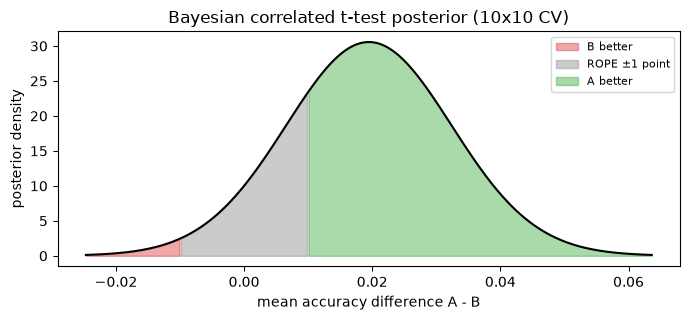

In [22]:
def bayesian_correlated_ttest(diffs, rho, rope=0.01):
    d = np.asarray(diffs, float); k = len(d)
    scale = np.sqrt((1 / k + rho / (1 - rho)) * d.var(ddof=1))
    post = stats.t(df=k - 1, loc=d.mean(), scale=scale)
    p_left, p_right = post.cdf(-rope), post.sf(rope)
    return {"P(B better)": p_left, "P(practically equivalent)": 1 - p_left - p_right, "P(A better)": p_right}, post

rho = 1 / 10                                                     # 10-fold CV: test fold = 1/10 of the data
probs, post = bayesian_correlated_ttest(d_cv, rho, rope=0.01)
# Check: the posterior scale equals the Nadeau-Bengio corrected standard error
nb_se = np.sqrt((1 / len(d_cv) + n_test_fold / n_train_fold) * d_cv.var(ddof=1))
assert np.isclose(post.std() * np.sqrt((len(d_cv) - 3) / (len(d_cv) - 1)), nb_se)
print({k: round(float(v), 3) for k, v in probs.items()})
print(f"95% credible interval for the mean difference: [{post.ppf(0.025):+.4f}, {post.ppf(0.975):+.4f}]")

xs = np.linspace(post.ppf(0.0005), post.ppf(0.9995), 400)
plt.figure(figsize=(7, 3.3))
plt.plot(xs, post.pdf(xs), color="black")
for lo, hi, col, lab in [(-1, -0.01, "tab:red", "B better"), (-0.01, 0.01, "tab:gray", "ROPE ±1 point"), (0.01, 1, "tab:green", "A better")]:
    m = (xs >= lo) & (xs <= hi)
    plt.fill_between(xs[m], post.pdf(xs[m]), alpha=0.4, color=col, label=f"{lab}")
plt.xlabel("mean accuracy difference A - B"); plt.ylabel("posterior density")
plt.title("Bayesian correlated t-test posterior (10x10 CV)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?** The posterior says: **P(A better by > 1 point) = 0.77**, P(practically equivalent) = 0.22, P(B better by > 1 point) = 0.01, and the 95% credible interval for the mean difference is [−0.006, +0.045]. This is a richer and more honest summary than "p = 0.138, not significant": B being meaningfully better is very unlikely, A is probably better by a practically relevant margin, but a 22% chance of practical equivalence remains. (The `baycomp` package implements this test and the hierarchical version for many datasets; it is optional and not needed here.)

## 7. Reporting results

> **In plain English:** Show ranges, say how you got them, round sensibly and never hide the bad runs.

### 7.1 Mean ± std, standard error or confidence interval?

| What you write | What it describes | When to use |
|---|---|---|
| mean ± **SD** (standard deviation) | the spread of *individual runs* (e.g. across seeds) | to show how much a single run can vary |
| mean ± **SE** (standard error = SD/√n) | the uncertainty of the *mean* | rarely on its own; easy to misread |
| mean with **95% CI** | a range for the true mean (≈ mean ± t·SE) | to support claims about which method is better |

**Always say which one you use** and over what (seeds? folds? test-set bootstrap?) and how many runs. "0.873 ± 0.012" without that information is uninterpretable.

### 7.2 Significant digits

Report no more digits than the uncertainty justifies. Rule: round the uncertainty to 1–2 significant digits, then round the estimate to the same decimal place.

In [23]:
def fmt_uncertain(value, unc, sig=2):
    # Round the uncertainty to `sig` significant digits and the value to the same decimal place
    if unc <= 0:
        return f"{value}"
    decimals = max(0, sig - 1 - int(np.floor(np.log10(abs(unc)))))
    return f"{value:.{decimals}f} ± {unc:.{decimals}f}"

for v, u in [(0.87654321, 0.0123456), (0.87654321, 0.00093), (91.236, 1.87), (0.5, 0.25)]:
    print(f"{v} ± {u}  ->  {fmt_uncertain(v, u)}")

0.87654321 ± 0.0123456  ->  0.877 ± 0.012
0.87654321 ± 0.00093  ->  0.87654 ± 0.00093
91.236 ± 1.87  ->  91.2 ± 1.9
0.5 ± 0.25  ->  0.50 ± 0.25


**What just happened?** 0.87654321 ± 0.0123456 becomes **0.877 ± 0.012**: the seventh decimal place is meaningless when the uncertainty is in the second. If a table shows 91.24 vs 91.19 with an SD of 1.9, the last digit carries no information, and the bolding that follows from it is noise.

### 7.3 Tables and bolding rules

Common bad practice: bold the highest number in each row even when the difference is far inside the noise. Better rules:

1. Bold the best result per dataset **and** every result not significantly worse than it (state the test and α in the caption), or mark the latter with a symbol.
2. Give the uncertainty (± SD over folds/seeds, or CIs) and the number of runs.
3. Add a summary row: average rank and win/tie/loss counts, plus the Friedman/Nemenyi result.
4. Round consistently (Section 7.2).

Below, the benchmark from Section 3 rendered as a paper-style table. For each dataset the best mean is **bold**, and † marks methods whose 5 fold scores are not significantly worse than the best (corrected resampled t-test, α = 0.05).

In [24]:
def results_table(bench, fold_acc, models_shown, alpha=0.05):
    lines = ["| dataset | " + " | ".join(models_shown) + " |", "|---|" + "---|" * len(models_shown)]
    n_dagger = 0
    for d in bench.index:
        best = bench.loc[d, models_shown].idxmax()
        cells = []
        for m in models_shown:
            s = fold_acc[(d, m)]
            txt = f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
            if m == best:
                txt = f"**{txt}**"
            else:
                _, p = resampled_ttest(fold_acc[(d, best)] - s, n_train=4, n_test=1, corrected=True)   # 5-fold: n_test/n_train = 1/4
                if p >= alpha:
                    txt += " †"; n_dagger += 1
            cells.append(txt)
        lines.append(f"| {d} | " + " | ".join(cells) + " |")
    lines.append("| **average rank** | " + " | ".join(f"{avg_rank[m]:.2f}" for m in models_shown) + " |")
    return "\n".join(lines), n_dagger

table_md, n_dagger = results_table(bench, fold_acc, list(models))
display(Markdown(table_md))
print(f"{n_dagger} non-best entries are not significantly worse than the best of their row (†).")

| dataset | NaiveBayes | kNN | LogReg | DecisionTree | RandomForest |
|---|---|---|---|---|---|
| iris | 0.960 ± 0.015 † | **0.960 ± 0.037** | 0.960 ± 0.015 † | 0.933 ± 0.047 † | 0.947 ± 0.018 † |
| wine | 0.972 ± 0.000 † | 0.955 ± 0.015 † | **0.983 ± 0.015** | 0.927 ± 0.057 † | 0.978 ± 0.023 † |
| breast_cancer | 0.939 ± 0.022 † | 0.965 ± 0.021 † | **0.979 ± 0.016** | 0.926 ± 0.024 | 0.961 ± 0.019 † |
| digits | 0.851 ± 0.028 | 0.974 ± 0.009 † | 0.969 ± 0.011 † | 0.859 ± 0.022 | **0.974 ± 0.011** |
| moons | 0.853 ± 0.053 † | 0.885 ± 0.027 † | 0.853 ± 0.053 † | 0.872 ± 0.043 † | **0.887 ± 0.042** |
| circles | **0.955 ± 0.014** | 0.953 ± 0.010 † | 0.450 ± 0.032 | 0.915 ± 0.036 † | 0.943 ± 0.029 † |
| synthetic_1 | 0.833 ± 0.033 | 0.790 ± 0.052 † | 0.847 ± 0.045 † | 0.827 ± 0.058 † | **0.863 ± 0.022** |
| synthetic_2 | 0.596 ± 0.040 | 0.664 ± 0.047 † | 0.598 ± 0.067 † | 0.634 ± 0.063 † | **0.674 ± 0.036** |
| synthetic_3 | **0.920 ± 0.039** | 0.797 ± 0.045 | 0.873 ± 0.054 † | 0.863 ± 0.047 † | 0.915 ± 0.029 † |
| synthetic_4 | 0.683 ± 0.054 | **0.810 ± 0.036** | 0.658 ± 0.068 | 0.720 ± 0.050 | 0.793 ± 0.022 † |
| synthetic_5 | 0.647 ± 0.084 † | 0.690 ± 0.053 † | 0.633 ± 0.035 † | 0.620 ± 0.103 † | **0.707 ± 0.043** |
| synthetic_6 | 0.679 ± 0.034 | 0.760 ± 0.030 | 0.766 ± 0.011 | 0.831 ± 0.020 † | **0.861 ± 0.007** |
| synthetic_7 | 0.848 ± 0.033 | 0.758 ± 0.020 | 0.864 ± 0.028 † | 0.796 ± 0.027 † | **0.874 ± 0.027** |
| synthetic_8 | 0.714 ± 0.035 † | 0.757 ± 0.047 † | 0.680 ± 0.019 | 0.674 ± 0.042 | **0.763 ± 0.013** |
| synthetic_9 | 0.811 ± 0.036 † | 0.698 ± 0.052 | 0.824 ± 0.028 † | 0.787 ± 0.020 | **0.853 ± 0.024** |
| **average rank** | 3.33 | 2.93 | 3.07 | 4.00 | 1.67 |

41 non-best entries are not significantly worse than the best of their row (†).


**What just happened?** The table shows the best result of each row in bold, but the † marks reveal how often the "winner" is not separable from the others: **41 of the 60** non-best entries are not significantly worse than the best of their row (with only 5 folds per dataset the corrected test has 4 degrees of freedom and is conservative). Counting bold cells would massively overstate the evidence; the multi-dataset analysis (average ranks, Friedman, CD diagram) is more informative.

### 7.4 Error bars and what they mean

The same 10 seed results drawn with three different error bars:

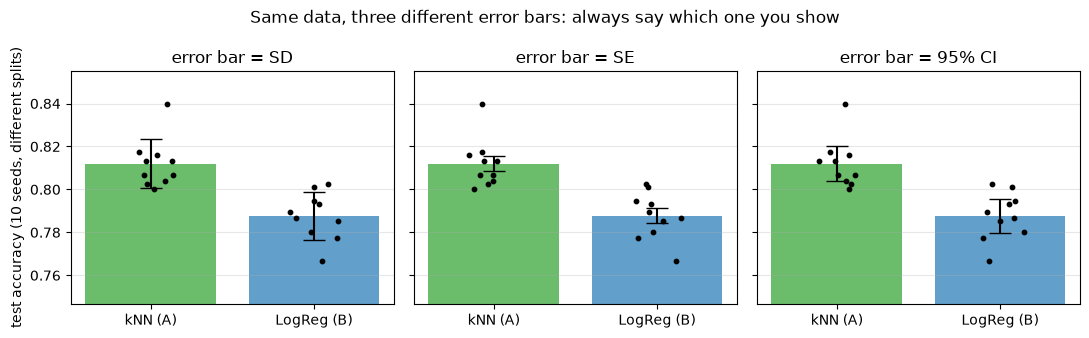

kNN (A)                  mean 0.8120  SD 0.0115  SE 0.0036
Logistic regression (B)  mean 0.7877  SD 0.0111  SE 0.0035
paired difference over the 10 splits: +0.0243, 95% CI [+0.0159, +0.0326]  (not corrected for overlapping training sets)


In [25]:
# The 10 split-seed results of Section 5 for both models
runs = {"kNN (A)": seed_acc_A, "Logistic regression (B)": seed_acc_B}
lo_y = min(r.min() for r in runs.values()) - 0.02; hi_y = max(r.max() for r in runs.values()) + 0.015
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, kind in zip(axes, ["SD", "SE", "95% CI"]):
    for i, (name, r) in enumerate(runs.items()):
        sd = r.std(ddof=1); se = sd / np.sqrt(len(r)); ci = stats.t.ppf(0.975, len(r) - 1) * se
        err = {"SD": sd, "SE": se, "95% CI": ci}[kind]
        ax.bar(i, r.mean(), yerr=err, capsize=8, color=["tab:green", "tab:blue"][i], alpha=0.7)
        ax.scatter(np.full(len(r), i) + rng.uniform(-0.15, 0.15, len(r)), r, color="black", s=10, zorder=3)
    ax.set_xticks([0, 1], ["kNN (A)", "LogReg (B)"]); ax.set_title(f"error bar = {kind}")
    ax.set_ylim(lo_y, hi_y); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("test accuracy (10 seeds, different splits)")
plt.suptitle("Same data, three different error bars: always say which one you show"); plt.tight_layout(); plt.show()
for name, r in runs.items():
    print(f"{name:<24} mean {r.mean():.4f}  SD {r.std(ddof=1):.4f}  SE {r.std(ddof=1) / np.sqrt(10):.4f}")
d_seed = runs["kNN (A)"] - runs["Logistic regression (B)"]
lo, hi = stats.t.interval(0.95, 9, loc=d_seed.mean(), scale=d_seed.std(ddof=1) / np.sqrt(10))
print(f"paired difference over the 10 splits: {d_seed.mean():+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]  (not corrected for overlapping training sets)")

**What just happened?** The bars and the dots (one per split) are identical in all three panels; only the error bar changes. **SD** bars show the run-to-run spread (kNN 0.812 ± 0.012, LogReg 0.788 ± 0.011); **SE** bars are √10 ≈ 3.2 times shorter (0.0036); **95% CI** bars are 2.26 times the SE. A reader who does not know which bar is shown can be misled in either direction. Also, **overlapping error bars do not mean "no significant difference"** and non-overlapping SE bars do not mean "significant": comparisons of models evaluated on the same splits must use the *paired* differences, whose 95% CI here is [+0.016, +0.033] (and, because the 10 training sets overlap, even this paired interval is somewhat too narrow; the corrected resampled t-test of Section 2.1 fixes that).

### 7.5 A results section written from the outputs

Numbers in the text should come straight from the analysis code, never be typed by hand. Here is a results paragraph generated with f-strings from the variables computed above (you would put this in your thesis, adapted to your style).

In [26]:
pb = paired_tbl
sig = lambda p: "statistically significant" if p < 0.05 else "not statistically significant"
pairs = [(a, b_) for i, a in enumerate(avg_rank.index) for b_ in avg_rank.index[i + 1:] if avg_rank[b_] - avg_rank[a] >= CD]
winners = sorted({w for w, _ in pairs}, key=lambda w: avg_rank[w])
nemenyi_sentence = "; ".join(
    f"{w} (average rank {avg_rank[w]:.2f}) was significantly better than "
    + " and ".join(f"{l} ({avg_rank[l]:.2f})" for ww, l in pairs if ww == w) for w in winners)
report = f'''
**Results.** On the held-out test set (n = {len(y_test):,}), the kNN classifier (A) reached an accuracy of
{corr_A.mean():.3f} (95% bootstrap CI {ci_A.loc["accuracy", "CI low"]:.3f}–{ci_A.loc["accuracy", "CI high"]:.3f}) and the logistic
regression (B) {corr_B.mean():.3f} ({ci_B.loc["accuracy", "CI low"]:.3f}–{ci_B.loc["accuracy", "CI high"]:.3f}). The paired accuracy
difference of {100 * pb.loc["accuracy", "A - B"]:+.1f} points (95% CI {100 * pb.loc["accuracy", "95% CI low"]:+.1f} to
{100 * pb.loc["accuracy", "95% CI high"]:+.1f}) was {sig(p_exact)} (exact McNemar test, b = {b}, c = {c}, p = {p_exact:.3f}).
For ranking quality (AUC {ci_A.loc["AUC", "estimate"]:.3f} vs {ci_B.loc["AUC", "estimate"]:.3f}) the paired difference was
{pb.loc["AUC", "A - B"]:+.3f} (95% CI {pb.loc["AUC", "95% CI low"]:+.3f} to {pb.loc["AUC", "95% CI high"]:+.3f}), {"which excludes" if pb.loc["AUC", "95% CI low"] > 0 else "which includes"} zero.
On the development set, comparing the two learning algorithms with 10 × 10-fold CV, the mean accuracy difference was
{100 * d_cv.mean():+.2f} points, which was {sig(p_corr)} (corrected resampled t-test, t({len(d_cv) - 1}) = {t_corr:.2f}, p = {p_corr:.3f}); the Bayesian correlated t-test with a ROPE of ±1 point gave
P(A better) = {probs["P(A better)"]:.2f}, P(equivalent) = {probs["P(practically equivalent)"]:.2f} and
P(B better) = {probs["P(B better)"]:.2f}. Across {len(bench)} benchmark datasets, average ranks differed significantly
(Friedman χ²({len(models) - 1}) = {chi2_F:.1f}, p = {p_F:.4f}); with a Nemenyi critical difference of {CD:.2f}, {nemenyi_sentence},
while the remaining differences were not significant. All tests were two-sided with α = 0.05.
'''
display(Markdown(report))


**Results.** On the held-out test set (n = 1,000), the kNN classifier (A) reached an accuracy of
0.828 (95% bootstrap CI 0.804–0.851) and the logistic
regression (B) 0.795 (0.770–0.819). The paired accuracy
difference of +3.3 points (95% CI +0.9 to
+5.9) was statistically significant (exact McNemar test, b = 96, c = 63, p = 0.011).
For ranking quality (AUC 0.889 vs 0.872) the paired difference was
+0.017 (95% CI -0.001 to +0.036), which includes zero.
On the development set, comparing the two learning algorithms with 10 × 10-fold CV, the mean accuracy difference was
+1.95 points, which was not statistically significant (corrected resampled t-test, t(99) = 1.50, p = 0.138); the Bayesian correlated t-test with a ROPE of ±1 point gave
P(A better) = 0.77, P(equivalent) = 0.22 and
P(B better) = 0.01. Across 15 benchmark datasets, average ranks differed significantly
(Friedman χ²(4) = 17.5, p = 0.0015); with a Nemenyi critical difference of 1.57, RandomForest (average rank 1.67) was significantly better than NaiveBayes (3.33) and DecisionTree (4.00),
while the remaining differences were not significant. All tests were two-sided with α = 0.05.


**What just happened?** Every number and every "significant / not significant" phrase in that paragraph was computed above, so the text cannot drift from the analysis when you re-run with new data. Notice the structure of each claim: **estimate + uncertainty + test name + test statistic/df + p-value**, and the non-significant results are reported as clearly as the significant ones, including the disagreement between the test-set and CV analyses.

### 7.6 Common statistical sins

| Sin | What it looks like | Fix |
|---|---|---|
| **p-hacking** | trying analyses (metrics, subsets, outlier rules, tests, stopping points) until p < 0.05 | pre-registered analysis plan; report everything you tried |
| **HARKing** (Hypothesising After the Results are Known) | presenting a post-hoc finding as if it had been the hypothesis all along | label exploratory findings as exploratory; confirm on new data |
| **cherry-picking seeds/datasets** | reporting the best seed of your method, or only the datasets where it wins | fixed seed list, report all runs and all datasets |
| **naive CV t-test** | paired t-test on (repeated) CV folds | corrected resampled t-test / 5×2cv (Section 2) |
| **no multiple-comparison correction** | 20 tests, 1 significant, celebrated | Holm/BH (Section 4) |
| **significance without effect size** | "p < 0.001" for a 0.05-point gain | effect size + CI |
| **"no significant difference" = "equal"** | underpowered test interpreted as equivalence | power analysis, equivalence tests or ROPE |
| **test-set reuse** | tuning on the test set | validation set; touch test once (notebook 2) |

Two quick simulations show how much these sins matter.

In [27]:
# (1) p-hacking: the forking paths of ONE null experiment (two equal models, 40 paired runs)
ph = np.random.default_rng(11)
def hacked_p_values(n=40):
    d = ph.normal(0, 1, n)                                       # truly no difference
    ps = [stats.ttest_1samp(d, 0).pvalue,                        # 1. the planned test
          stats.wilcoxon(d).pvalue,                              # 2. "maybe a non-parametric test"
          stats.ttest_1samp(d[np.abs(d) < 2 * d.std()], 0).pvalue,   # 3. "remove outliers"
          stats.ttest_1samp(d[: n // 2], 0).pvalue,              # 4. "only the first half (old data)"
          stats.ttest_1samp(d[n // 2:], 0).pvalue,               # 5. "only the second half (new data)"
          stats.ttest_1samp(np.sign(d) * np.log1p(np.abs(d)), 0).pvalue]   # 6. "log-transform"
    if 0.05 < ps[0] < 0.15:                                      # 7. "almost significant: collect 20 more runs"
        ps.append(stats.ttest_1samp(np.concatenate([d, ph.normal(0, 1, 20)]), 0).pvalue)
    return min(ps)
hacked = np.array([hacked_p_values() for _ in range(1000)])
print(f"p-hacking: 'significant' in {np.mean(hacked < 0.05):.1%} of null experiments (honest single test: 5%)")

# (2) cherry-picking seeds: both methods have the SAME true accuracy 0.850, seed SD 0.005
cp = np.random.default_rng(12)
ours = cp.normal(0.85, 0.005, size=(5000, 10)); theirs = cp.normal(0.85, 0.005, size=(5000, 10))
fake_gain = ours.max(1) - theirs.mean(1)                         # "our best seed vs their average"
print(f"cherry-picked 'gain' of an identical method: mean {100 * fake_gain.mean():+.2f} points, "
      f"positive in {np.mean(fake_gain > 0):.1%} of studies")

p-hacking: 'significant' in 14.2% of null experiments (honest single test: 5%)
cherry-picked 'gain' of an identical method: mean +0.77 points, positive in 99.3% of studies


**What just happened?**
- Trying up to 7 reasonable-sounding analyses on data with **no effect** produced a "significant" result in **14.2%** of experiments, about three times the promised 5%, and every individual choice could be defended in a paper.
- Comparing **your best seed** with **the baseline's average** manufactures a gain of **+0.77 points** (about 1.5 seed-SDs) for an identical method, and the "gain" is positive in 99.3% of studies. That is larger than many published improvements.

## 8. 🔗 How this connects to modern AI

> **In plain English:** LLM benchmarks and leaderboards need exactly these tools.

- **LLM benchmarks:** differences of 0.5–1 point on benchmarks with a few hundred to a few thousand questions are often inside the noise. Report bootstrap CIs or paired tests across questions (Section 2), several seeds/samples for stochastic decoding, and correct for the many benchmarks you report (Section 4). See [LLM evaluation](../08_LLM/08_evaluation/01_llm_evaluation.ipynb).
- **Arena-style leaderboards** (pairwise human votes, Bradley–Terry/Elo scores) publish confidence intervals for ratings: two models with overlapping intervals share a rank band. Read them like the CD diagram.
- **LLM-as-judge** evaluations are permutation-test friendly: swap the order of the two answers (position bias), use per-item scores, and report paired CIs.
- **Model selection in production** uses the same tools: champion/challenger with paired bootstrap ([industry model comparison](../03_Machine_Learning/06_model_evaluation/03_industry_model_comparison_and_selection.ipynb)) and online A/B tests ([A/B testing](../03_Machine_Learning/11_ab_testing/01_ab_testing.ipynb), [industry A/B report](../03_Machine_Learning/11_ab_testing/02_industry_ab_test_analysis_report.ipynb)).
- **Reproducibility checklists** (NeurIPS paper checklist, ACL Responsible NLP checklist) explicitly ask about error bars, how they were computed, and the number of runs.

## Recap

- A **p-value** is P(data at least this extreme | H0). It is not P(H0), not an effect size, and p > 0.05 is not proof of equality. Report **effect sizes with CIs**.
- **Two models, CV:** the naive paired t-test on folds is badly optimistic (52.5% false positives in our simulation). Use the **corrected resampled t-test** (Nadeau–Bengio) or **5×2cv** (Dietterich / Alpaydın F).
- **Two models, one test set:** **McNemar** for accuracy; **paired bootstrap** CIs and **permutation tests** for any metric. Separate CIs per model are the wrong comparison.
- **Many models, many datasets:** **Friedman** on ranks, **Nemenyi** critical difference, **CD diagram**; Wilcoxon for two methods across datasets.
- **Multiple comparisons:** 20 null tests give at least one false positive 64% of the time. **Holm** controls FWER (prefer it over Bonferroni); **BH** controls FDR.
- **Effect sizes:** Cohen's d (and d_z, Hedges' g), Cliff's delta.
- **Bayesian correlated t-test + ROPE** gives P(A better), P(equivalent), P(B better).
- **Reporting:** say SD vs SE vs CI and over what; round to the uncertainty; bold only what is supported; generate the text from the code; avoid p-hacking, HARKing and cherry-picking.

## Practice problems

**1. (Easy, conceptual)** A paper says: "p = 0.01, so there is a 99% probability that our model is better." Correct the sentence.

<details><summary>Show solution</summary>

"If the two models had equal expected performance, a difference at least as large as ours would occur with probability 0.01." The probability that the model is better requires a Bayesian analysis with a prior (Section 6). Also report the size of the difference with a CI.
</details>

**2. (Easy, coding)** Apply Holm and BH to p = [0.001, 0.012, 0.03, 0.04, 0.2] at α = 0.05. Which hypotheses are rejected?

<details><summary>Show solution</summary>

```python
p = [0.001, 0.012, 0.03, 0.04, 0.2]
print(holm(p).round(3))                # [0.005 0.048 0.09  0.09  0.2  ] -> reject H1, H2
print(benjamini_hochberg(p).round(3))  # [0.005 0.03  0.05  0.05  0.2  ] -> reject H1, H2 (0.05 is not < 0.05)
```
Both reject the first two. BH's adjusted values for H3 and H4 are exactly 0.05, so they are not rejected at "p < 0.05" (under the "≤ α" convention used by some software they would be).
</details>

**3. (Medium, coding)** Two classifiers on the same 500 test examples: A is right and B wrong on 30 examples, B right and A wrong on 15. Compute the exact McNemar p-value.

<details><summary>Show solution</summary>

```python
p = min(1, 2 * stats.binom.cdf(15, 45, 0.5))
print(round(p, 4))   # 0.0357
```
Only the 45 discordant examples matter; p ≈ 0.036 < 0.05, so A's higher accuracy (+3 points) is significant at the 5% level.
</details>

**4. (Medium, conceptual)** Why does adding more repetitions to repeated 10-fold CV make the *naive* paired t-test more likely to declare significance, even though no new data is collected?

<details><summary>Show solution</summary>

The naive standard error is s/√k. More repetitions increase k, so the denominator shrinks and t grows, but the fold scores are highly correlated (they reuse the same examples), so the real uncertainty of the mean barely decreases. The corrected test adds n_test/n_train to 1/k, a term that does not shrink with k, which keeps the standard error realistic.
</details>

**5. (Medium, coding)** Compute Cliff's delta and Cohen's d for x = [0.81, 0.83, 0.82, 0.85, 0.84] and y = [0.80, 0.82, 0.79, 0.81, 0.80]. Interpret both.

<details><summary>Show solution</summary>

```python
x = [0.81, 0.83, 0.82, 0.85, 0.84]; y = [0.80, 0.82, 0.79, 0.81, 0.80]
print(cliffs_delta(x, y), round(cohens_d(x, y), 2))   # 0.84 and 1.89
```
Cliff's δ = 0.84 (large: a value of x exceeds a value of y in most pairs); Cohen's d ≈ 1.89 (very large). Both describe size only; with n = 5 per group a test is still needed, and if these came from the same splits a paired analysis is better.
</details>

**6. (Hard, coding)** Using `friedman_nemenyi`, compute the CD for k = 5 methods if you had 50 datasets instead of 15. Would RandomForest and kNN (average-rank gap ≈ 1.26) then be significantly different, assuming the same ranks?

<details><summary>Show solution</summary>

```python
q = stats.studentized_range.ppf(0.95, 5, np.inf) / np.sqrt(2)
print(round(q * np.sqrt(5 * 6 / (6 * 50)), 3))   # 0.863
```
CD shrinks with √N: from 1.58 (N = 15) to 0.86 (N = 50). A gap of 1.26 > 0.86 would be significant (it is not with N = 15, since 1.26 < 1.58). More datasets, not more folds, is what gives power in multi-dataset comparisons.
</details>

**7. (Hard, conceptual)** A student reports: "Our method is best on 7 of 10 datasets (bold in Table 2)." List what is missing and what to add.

<details><summary>Show solution</summary>

Missing: uncertainty per cell (SD over seeds/folds and the number of runs), whether the bolded wins are significant (mark ties with †), how many methods/datasets were tried and dropped, the tuning budget per method. Add: average ranks and win/tie/loss counts, a Friedman test with Nemenyi CD diagram (or Holm vs the proposed method as control), Wilcoxon signed-rank for the head-to-head against the strongest baseline, effect sizes, and a statement that all seeds and datasets are reported.
</details>

In [28]:
# Verify the practice-problem code solutions
p = [0.001, 0.012, 0.03, 0.04, 0.2]
assert np.allclose(holm(p).round(3), [0.005, 0.048, 0.09, 0.09, 0.2])
assert np.allclose(benjamini_hochberg(p).round(3), [0.005, 0.03, 0.05, 0.05, 0.2])
assert round(min(1, 2 * stats.binom.cdf(15, 45, 0.5)), 4) == 0.0357
x5, y5 = [0.81, 0.83, 0.82, 0.85, 0.84], [0.80, 0.82, 0.79, 0.81, 0.80]
assert np.isclose(cliffs_delta(x5, y5), 0.84) and round(cohens_d(x5, y5), 2) == 1.89, (cliffs_delta(x5, y5), cohens_d(x5, y5))
q5 = stats.studentized_range.ppf(0.95, 5, np.inf) / np.sqrt(2)
assert round(q5 * np.sqrt(5 * 6 / (6 * 50)), 3) == 0.863
print("all practice solutions verified")
print(f"total notebook runtime: {time.time() - T0:.0f} s")

all practice solutions verified
total notebook runtime: 94 s


## Further reading

- J. Demšar, "Statistical Comparisons of Classifiers over Multiple Data Sets", *JMLR* 7, 2006 (free): Friedman, Nemenyi, Wilcoxon, CD diagrams.
- T. G. Dietterich, "Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms", *Neural Computation* 10(7), 1998: McNemar and 5×2cv.
- C. Nadeau & Y. Bengio, "Inference for the Generalization Error", *Machine Learning* 52, 2003: the corrected resampled t-test.
- A. Benavoli, G. Corani, J. Demšar & M. Zaffalon, "Time for a Change: a Tutorial for Comparing Multiple Classifiers Through Bayesian Analysis", *JMLR* 18, 2017 (free).
- R. Dror, G. Baumer, S. Shlomov & R. Reichart, "The Hitchhiker's Guide to Testing Statistical Significance in NLP", ACL 2018 (free).
- B. Efron & R. Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall, 1993; Y. Benjamini & Y. Hochberg, *JRSS B*, 1995 (FDR).
- R. L. Wasserstein & N. A. Lazar, "The ASA Statement on p-Values: Context, Process, and Purpose", *The American Statistician*, 2016 (free).
- Free online: S. Raschka, "Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning" (arXiv:1811.12808); the SciPy `scipy.stats` documentation for `bootstrap` and `permutation_test`.

## Next notebook

➡️ [04 – Reproducibility and research code](04_reproducibility_and_research_code.ipynb): make sure every number in your results section can be regenerated by someone else.

Practice ideas before you move on:
- re-analyse one of the [end-to-end projects](../21_Projects/01_ml_pipeline) with seeds, a paired bootstrap and an ablation table;
- write an experiment plan ([notebook 2, Section 7](02_experiment_design_for_ml.ipynb)) for your own thesis idea from [notebook 1](01_research_methodology_and_literature_review.ipynb).